# S&P 500 share segmentation: risk-return vs adapted RFM
**6BUIS017W CRM & CM with Business Intelligence, individual coursework 1**

This notebook segments S&P 500 shares in two ways and compares them:
- **Risk and return:** mean weekly return and weekly beta against the S&P 500 (^GSPC).
- **Trading activity (adapted RFM):** Recency, Frequency and Monetary values built from unusually high-volume days.

Study window: 1 Jan 2021 to 1 Jan 2025 (end date exclusive). Observation date for RFM: the last common trading day.

## Contents
| Part | Brief section | What it covers | |
|---|---|---|---|
| Setup | n/a | Installs packages in Colab | |
| Task 1 | 1.1 to 1.5 | Download, validation, weekly return and beta, R/F/M, worked example | |
| Task 2 | 2.1 to 2.5 | Feature prep, Ward and K-means (k = 2 to 8), profiles, correlation and Monetary-removal sensitivity ||
| Task 3.2 | 3.2.1 to 3.2.3 | Sector mix, risk-return vs RFM agreement, return dependence, price-basis and survivorship checks ||


## How to run
1. **Run all cells from top to bottom.** Each part reads the files written by the part before it, so the order matters.
2. **Data source (automatic):** if the saved snapshot is in `data/raw/`, it is reused, which reproduces the reported numbers exactly. If not (for example, this notebook opened on its own in Colab), the data are downloaded live from Wikipedia and Yahoo Finance. Downloading needs internet and takes a few minutes.
   - To force one or the other, set the environment variable `CW1_USE_CACHE` to `1` (snapshot) or `0` (live download) before running Task 1.
   - A live download gives today's constituent list and Yahoo's current adjusted prices, so a few numbers can differ slightly from the report.
3. **Outputs** are written next to the notebook: `data/raw/`, `data/processed/`, `tables/`, `figures/`



> **Setup**
>
> **Brief:** Packages must be available before anything runs.
>
> **This cell:** In Google Colab, installs `yfinance`, `pyarrow`, `lxml` and `html5lib` (the rest are preinstalled). Does nothing when run locally.
>
> **Output:** Nothing saved.

In [1]:
# Setup: install packages if running in Google Colab (locally, use: pip install -r requirements.txt)
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance", "pyarrow", "lxml", "html5lib"], check=True)

---
# TASK 1: Data preparation and feature engineering


> **Task 1 · Configuration**

> **This cell:** Sets the study window (2021-01-01 to 2025-01-01, end exclusive), the 20-session baseline, 60-session window, 2x volume multiplier and seed. Chooses snapshot or live download. Creates the output folders and records package versions.
>
> **Output:** `tables/package_versions.txt`; prints the data source being used.

In [2]:
# CONFIG (change parameters here only)
import io, json, sys, time, platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

START = "2021-01-01"
END = "2025-01-01"          # exclusive (yfinance convention)
BASELINE = 20               # sessions in the rolling volume baseline
WINDOW = 60                 # sessions for Frequency and Monetary
MULT = 2.0                  # high-volume multiplier
SEED = 42
K_RANGE = range(2, 9)
import os
CHUNK = 50                  # tickers per yfinance request

ROOT = Path(".")
RAW, PROC, TAB, FIG = ROOT/"data/raw", ROOT/"data/processed", ROOT/"tables", ROOT/"figures"

# Data source switch.
#   CW1_USE_CACHE=1 -> always reload the preserved snapshot in data/raw (offline, reproduces the reported numbers)
#   CW1_USE_CACHE=0 -> always download live from Wikipedia and Yahoo Finance
#   not set         -> use the snapshot if it is present, otherwise download (so the notebook runs on its own)
SNAPSHOT = [RAW/"sp500_constituents.csv", RAW/"retrieval_metadata.json", RAW/"prices_daily.parquet", RAW/"gspc_daily.csv"]
_env = os.environ.get("CW1_USE_CACHE")
USE_CACHE = (_env == "1") if _env in ("0", "1") else all(p.exists() for p in SNAPSHOT)
print("Data source:", "saved snapshot in data/raw" if USE_CACHE else "live download (Wikipedia + Yahoo Finance)")
for d in (RAW, PROC, TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)

import yfinance as yf
import sklearn, scipy, matplotlib
versions = {"python": sys.version.split()[0], "platform": platform.platform(),
            "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__}
(TAB/"package_versions.txt").write_text("\n".join(f"{k}=={v}" for k, v in versions.items()))
print(versions)

excl_log = []   # every exclusion and warning goes here
def log(ticker, stage, rule, detail, action):
    excl_log.append(dict(ticker=ticker, stage=stage, rule=rule, detail=detail, action=action))

Data source: live download (Wikipedia + Yahoo Finance)
{'python': '3.13.18', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}


> **Task 1.1 · Ticker selection and data acquisition (part a)** ·
>
>
>
> **This cell:** Retrieves the S&P 500 constituent table from Wikipedia (503 listings) with a UTC timestamp and standardizes dot-separated tickers (BRK.B, BF.B) to Yahoo Finance hyphenated format.
>
> **Output:** `data/raw/sp500_constituents.csv`, `data/raw/retrieval_metadata.json`; prints the count and symbol changes.

In [3]:
# 1.1a Constituent list from Wikipedia
WIKI = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
CONS_FILE = RAW/"sp500_constituents.csv"
META_FILE = RAW/"retrieval_metadata.json"

if USE_CACHE:
    cons = pd.read_csv(CONS_FILE)
    retrieval = json.loads(META_FILE.read_text())
else:
    html = requests.get(WIKI, headers={"User-Agent": "Mozilla/5.0 (university coursework, pandas read_html)"},
                        timeout=30)
    html.raise_for_status()
    cons = pd.read_html(io.StringIO(html.text))[0]
    retrieval = {"wikipedia_url": WIKI,
                 "retrieved_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                 "n_rows": int(len(cons))}
    cons.to_csv(CONS_FILE, index=False)
    META_FILE.write_text(json.dumps(retrieval, indent=2))

cons = cons.rename(columns={"Symbol": "wiki_symbol", "Security": "company", "GICS Sector": "sector",
                            "GICS Sub-Industry": "sub_industry", "Date added": "date_added", "CIK": "cik"})
cons["ticker"] = cons["wiki_symbol"].str.replace(".", "-", regex=False)   # BRK.B -> BRK-B
changed = cons[cons.ticker != cons.wiki_symbol]
print("Retrieved:", retrieval["retrieved_utc"], "| constituents:", len(cons))
print("Ticker symbol changes for Yahoo:\n", changed[["wiki_symbol", "ticker"]].to_string(index=False))
for _, r in changed.iterrows():
    log(r.ticker, "1.1", "ticker_format", f"{r.wiki_symbol} -> {r.ticker}", "INFO")

tickers = cons["ticker"].tolist()

Retrieved: 2026-11-24T10:54:06+00:00 | constituents: 503
Ticker symbol changes for Yahoo:
 wiki_symbol ticker
      BRK.B  BRK-B
       BF.B   BF-B


> **Task 1.1 · Ticker selection and data acquisition (part b)** · *4 marks*
>
>
>
> **This cell:** Downloads in chunks of 50 with retries, using `auto_adjust=False` so Close, Adj Close and Volume are all kept, along with dividends and splits. Logs failed tickers as exclusions.
>
> **Output:** `data/raw/prices_daily.parquet`, `data/raw/gspc_daily.csv`; prints rows and date range.

In [4]:
# 1.1b Download daily prices (auto_adjust=False keeps Close AND Adj Close)
PRICE_FILE = RAW/"prices_daily.parquet"
BENCH_FILE = RAW/"gspc_daily.csv"

def download_chunk(tk, retries=3):
    for a in range(retries):
        try:
            d = yf.download(tk, start=START, end=END, auto_adjust=False, actions=True,
                            group_by="ticker", progress=False, threads=True)
            if d is not None and not d.empty:
                return d
        except Exception as e:
            print("retry", a, e)
        time.sleep(5 * (a + 1))
    return None

def to_long(d, tk):
    if not isinstance(d.columns, pd.MultiIndex):
        d.columns = pd.MultiIndex.from_product([[tk[0]], d.columns])
    out = []
    for t in tk:
        if t in d.columns.get_level_values(0):
            x = d[t].copy()
            x["Ticker"] = t
            out.append(x.reset_index())
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

if USE_CACHE:
    prices = pd.read_parquet(PRICE_FILE)
    bench = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True)
else:
    parts, failed = [], []
    for i in range(0, len(tickers), CHUNK):
        tk = tickers[i:i + CHUNK]
        d = download_chunk(tk)
        if d is None:
            failed += tk
            continue
        parts.append(to_long(d, tk))
        print(f"downloaded {i + len(tk)}/{len(tickers)}")
    prices = pd.concat(parts, ignore_index=True)
    prices = prices.rename(columns={"Date": "date"})
    prices["date"] = pd.to_datetime(prices["date"])
    for t in failed:
        log(t, "1.1", "download_failed", "no data returned after retries", "EXCLUDE")
    b = yf.download("^GSPC", start=START, end=END, auto_adjust=False, progress=False)
    if isinstance(b.columns, pd.MultiIndex):
        b.columns = b.columns.get_level_values(0)
    bench = b
    prices.to_parquet(PRICE_FILE, index=False)
    bench.to_csv(BENCH_FILE)

prices["date"] = pd.to_datetime(prices["date"])
print(prices.shape, "| benchmark rows:", len(bench), "| range:", prices.date.min().date(), "->", prices.date.max().date())

downloaded 50/503
downloaded 100/503
downloaded 150/503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


downloaded 200/503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


downloaded 250/503
downloaded 300/503
downloaded 350/503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


downloaded 400/503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


downloaded 450/503


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


downloaded 500/503
downloaded 503/503
(505515, 10) | benchmark rows: 1005 | range: 2021-01-04 -> 2024-12-31


> **Task 1.2 · Data validation and alignment**
>
>
>
> **This cell:** Runs every check per share. Shares failing a rule are excluded and logged; nothing is forward-filled. Splits are checked for unadjusted price jumps (>40%), and Adj Close vs Close gaps away from dividend/split dates are flagged.
>
> **Output:** Excludes 17 shares (5 with no data, 10 with unequal history, 2 with volume errors) and aligns the remaining 486 shares onto the exact 1,005-day ^GSPC trading calendar.

In [5]:
# 1.2 Validation
bench_idx = bench.index
assert bench_idx.is_unique and bench_idx.min() >= pd.Timestamp(START) and bench_idx.max() < pd.Timestamp(END)
FIELDS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
valid, by_ticker = [], {t: g for t, g in prices.groupby("Ticker")}

for t in tickers:
    g = by_ticker.get(t)
    if g is None:
        log(t, "1.2", "no_data", "ticker absent from download", "EXCLUDE")
        continue
    n_raw = len(g)
    g = g.dropna(subset=FIELDS, how="all")                    # drops pre-listing padding only; no filling
    if n_raw != len(g):
        log(t, "1.2", "padding_rows_dropped", f"{n_raw - len(g)} all-NaN rows", "INFO")
    if g.empty:
        log(t, "1.2", "no_data", "all rows empty", "EXCLUDE"); continue
    ok = True
    dups = int(g.date.duplicated().sum())
    if dups:
        log(t, "1.2", "duplicate_dates", f"{dups} duplicates", "EXCLUDE"); ok = False
    g = g.set_index("date").sort_index()
    g = g[~g.index.duplicated(keep="first")]
    nmiss = int(g[["Close", "Adj Close", "Volume"]].isna().any(axis=1).sum())
    if nmiss:
        log(t, "1.2", "missing_values", f"{nmiss} days with NaN Close/AdjClose/Volume", "EXCLUDE"); ok = False
    npos = int(((g[["Open", "High", "Low", "Close", "Adj Close"]] <= 0).any(axis=1)).sum())
    if npos:
        log(t, "1.2", "nonpositive_price", f"{npos} days", "EXCLUDE"); ok = False
    nvol = int(((g.Volume < 0) | (g.Volume == 0)).sum())
    if nvol:
        log(t, "1.2", "volume_error", f"{nvol} days with zero/negative volume", "EXCLUDE"); ok = False
    missing_dates = bench_idx.difference(g.index)
    if len(missing_dates):
        first = g.index.min().date()
        late = first > bench_idx.min().date()
        log(t, "1.2", "unequal_history",
            f"{len(missing_dates)} benchmark days absent; first obs {first}" + (" (late listing)" if late else " (gaps)"),
            "EXCLUDE"); ok = False
    extra = g.index.difference(bench_idx)
    if len(extra):
        log(t, "1.2", "dates_not_in_benchmark", f"{len(extra)} extra dates", "WARN")
    # corporate actions
    if ok:
        splits = g.index[g["Stock Splits"].fillna(0) > 0]
        r = g.Close.pct_change()
        for sd in splits:
            win = r.loc[sd - pd.Timedelta(days=5): sd + pd.Timedelta(days=5)]
            worst = win.abs().max()
            ratio = float(g.loc[sd, "Stock Splits"])
            if worst > 0.40:
                log(t, "1.2", "split_price_jump", f"split {ratio}:1 on {sd.date()}, max |ret| {worst:.2f}: Close not split-adjusted?", "EXCLUDE"); ok = False
            else:
                log(t, "1.2", "split_checked", f"split {ratio}:1 on {sd.date()}, max |ret| {worst:.2f}", "INFO")
        # Adj Close vs Close should only diverge on dividend/split events
        rr = g["Adj Close"].pct_change() - r
        evdays = g.index[(g["Dividends"].fillna(0) > 0) | (g["Stock Splits"].fillna(0) > 0)]
        # adjustment shows on the day BEFORE ex-date in some data; allow +-1 session
        near = set()
        for e in evdays:
            loc = g.index.get_loc(e)
            near.update(g.index[max(0, loc - 1): loc + 2])
        unexplained = rr[(rr.abs() > 0.01) & (~rr.index.isin(near))]
        if len(unexplained):
            log(t, "1.2", "adjustment_inconsistency",
                f"{len(unexplained)} days where AdjClose/Close returns differ >1% away from dividend/split dates", "WARN")
    if ok:
        valid.append(t)

print("Valid after 1.2:", len(valid), "of", len(tickers))

Valid after 1.2: 486 of 503


> **Task 1.2 · Alignment** ·
>
>
>
> **This cell:** Builds date x share tables for Close, Adj Close and Volume on the benchmark's trading calendar, asserts there are no gaps, and confirms ^GSPC Adj Close equals Close (it is a price index).
>
>

In [6]:
# 1.2b Build aligned panels (dates x tickers) for retained shares
sub = prices[prices.Ticker.isin(valid)]
close = sub.pivot(index="date", columns="Ticker", values="Close").reindex(bench_idx)[valid]
adj = sub.pivot(index="date", columns="Ticker", values="Adj Close").reindex(bench_idx)[valid]
vol = sub.pivot(index="date", columns="Ticker", values="Volume").reindex(bench_idx)[valid]
assert not close.isna().any().any() and not adj.isna().any().any() and not vol.isna().any().any()
bench_adj = bench["Adj Close"] if "Adj Close" in bench else bench["Close"]
bench_note = "Adj Close" if "Adj Close" in bench else "Close"
print("Benchmark price basis:", bench_note, "(^GSPC is a price index; Adj Close == Close expected)")
print("Max |Adj-Close| on benchmark:", float((bench["Adj Close"] - bench["Close"]).abs().max()) if "Adj Close" in bench else "n/a")

Benchmark price basis: Adj Close (^GSPC is a price index; Adj Close == Close expected)
Max |Adj-Close| on benchmark: 0.0


> **Task 1.3.1 · Mean weekly return**
>
>
>
> **This cell:** Resamples with `W-FRI` and drops incomplete edge weeks. Asserts share and benchmark week labels are identical. Computes weekly returns and their arithmetic mean.
>
> **Output:** Prints the number of weekly prices and returns (expected 208 and 207) and the first and last week.

In [7]:
# 1.3 Weekly returns (Friday-ending weeks, last available trading price)
def weekly_prices(df):
    w = df.resample("W-FRI").last()
    # drop incomplete first/last calendar weeks, keep holiday-shortened ones
    week_monday = w.index - pd.Timedelta(days=4)
    keep = (week_monday >= pd.Timestamp(START)) & (w.index <= pd.Timestamp(END) - pd.Timedelta(days=1))
    return w[keep]

w_adj = weekly_prices(adj)
w_bench = weekly_prices(bench_adj.to_frame("^GSPC"))["^GSPC"]
assert w_adj.index.equals(w_bench.index), "weekly labels differ between shares and benchmark"
assert not w_adj.isna().any().any()
ret = w_adj.pct_change().iloc[1:]                    # first week has no preceding price
ret_m = w_bench.pct_change().iloc[1:]
assert ret.index.equals(ret_m.index)
n_weeks = len(ret)
print(f"Weekly prices: {len(w_adj)} ({w_adj.index[0].date()} -> {w_adj.index[-1].date()}); weekly returns: {n_weeks}")

mean_ret = ret.mean()                                 # arithmetic mean weekly return

Weekly prices: 208 (2021-01-08 -> 2024-12-27); weekly returns: 207


> **Task 1.3.2 · Weekly beta** ·
>
>
>
> **This cell:** Computes beta with `ddof=1` throughout, then checks it independently against an OLS slope (`np.polyfit`) and asserts they agree. Also computes each beta's standard error.
>
> **Output:** Prints the check result and the median beta.

In [8]:
# 1.3.2 Weekly beta = cov(r_i, r_m) / var(r_m), plus independent OLS check
beta = ret.apply(lambda s: s.cov(ret_m)) / ret_m.var()          # ddof=1 in both
slope = pd.Series({t: np.polyfit(ret_m.values, ret[t].values, 1)[0] for t in ret.columns})
assert np.allclose(beta.values, slope.values), "beta formula disagrees with OLS slope"
corr_m = ret.apply(lambda s: s.corr(ret_m))
beta_se = np.sqrt((1 - corr_m**2) / (n_weeks - 2)) * ret.std() / ret_m.std()
print("Beta check vs OLS slope: OK | median beta", round(beta.median(), 3))

Beta check vs OLS slope: OK | median beta 0.951


> **Task 1.4 · Adapted RFM (Recency 1.4.1, Frequency 1.4.2, Monetary 1.4.3)** ·
>
>
>
> **This cell:** Flags events per share per day with `shift(1)` so there is no look-ahead. Runs unit tests on the brief's own examples (5 days, same day = 0, 2.5M/2.0M/1.8M). Calculates R, F and M, re-counts F with a slow loop as an independent check, and logs shares with no event.
>
> **Output:** Prints the observation date and test results.

In [9]:
# 1.4 Adapted RFM
obs_date = close.index.max()
print("Observation date:", obs_date.date())

def event_flags(v, baseline=BASELINE, mult=MULT):
    """v: volume DataFrame/Series. Threshold = mult * mean of previous `baseline` sessions
    (current day excluded via shift(1)); strictly greater. NaN baseline -> not testable (False)."""
    base = v.shift(1).rolling(baseline, min_periods=baseline).mean()
    return (v > mult * base) & base.notna(), base

def recency_days(event_dates, obs):
    if len(event_dates) == 0:
        return np.nan
    return (obs - max(event_dates)).days

# --- unit tests (brief's examples)
assert recency_days([pd.Timestamp("2024-09-15")], pd.Timestamp("2024-09-20")) == 5
assert recency_days([pd.Timestamp("2024-09-20")], pd.Timestamp("2024-09-20")) == 0
assert np.isnan(recency_days([], pd.Timestamp("2024-09-20")))
tv = pd.Series([1e6] * 20 + [2.5e6, 2.0e6, 1.8e6], index=pd.bdate_range("2024-01-01", periods=23))
tf, _ = event_flags(tv)
assert tf.iloc[20] and not tf.iloc[21] and not tf.iloc[22], "threshold test failed (strict >2x, 2.0M not an event)"
print("Unit tests passed")

events, baseline_mean = event_flags(vol)
sessions = len(vol)
assert sessions >= BASELINE + WINDOW

R = pd.Series({t: recency_days(events.index[events[t]], obs_date) for t in vol.columns})
last_event = pd.Series({t: (events.index[events[t]].max() if events[t].any() else pd.NaT) for t in vol.columns})
win = slice(-WINDOW, None)
base_ok = bool(baseline_mean.iloc[win].notna().all().all())        # every window day has a full 20-session baseline
F = events.iloc[win].sum()
M = (close * vol).iloc[win].sum()

# independent slow check of F for a few shares
for t in vol.columns[:5]:
    v = vol[t].values; cnt = 0
    for i in range(sessions - WINDOW, sessions):
        if v[i] > MULT * v[i - BASELINE:i].mean():
            cnt += 1
    assert cnt == F[t], f"F mismatch for {t}"
print("Independent loop check of F passed")

noevent = R[R.isna()].index
for t in noevent:
    log(t, "1.4", "no_event", "no high-volume day in valid history: R missing", "EXCLUDE_RFM")

Observation date: 2024-12-31
Unit tests passed
Independent loop check of F passed


> **Task 1 · Feature table deliverable**
>
>
>
> **This cell:** Combines return, beta, R, F and M with company and sector, and marks which shares are valid for each matrix and for the common set. Saves supporting data.
>
> **Output:** `data/processed/feature_table.csv`, `weekly_returns*.parquet`, `event_flags.parquet`, `exclusion_log.csv`, `run_metadata.json`.

In [10]:
# Feature table (one row per included share)
feat = pd.DataFrame({
    "mean_weekly_return": mean_ret, "beta": beta, "beta_se": beta_se, "n_weeks": n_weeks,
    "R": R, "F": F, "M_usd": M, "last_event_date": last_event})
feat = feat.join(cons.set_index("ticker")[["company", "sector", "sub_industry"]])
feat["valid_riskreturn"] = feat[["mean_weekly_return", "beta"]].notna().all(axis=1)
feat["valid_rfm"] = feat[["R", "F", "M_usd"]].notna().all(axis=1)
feat["common_set"] = feat.valid_riskreturn & feat.valid_rfm
feat.index.name = "ticker"
feat.to_csv(PROC/"feature_table.csv")
ret.to_parquet(PROC/"weekly_returns.parquet"); ret_m.to_frame("^GSPC").to_parquet(PROC/"weekly_returns_benchmark.parquet")
events.to_parquet(PROC/"event_flags.parquet")
pd.DataFrame(excl_log).to_csv(PROC/"exclusion_log.csv", index=False)

run_meta = {"observation_date": str(obs_date.date()), "n_trading_sessions": sessions, "n_weekly_returns": n_weeks,
            "first_week": str(ret.index[0].date()), "last_week": str(ret.index[-1].date()),
            "n_constituents_listed": len(tickers), "n_valid_after_validation": len(valid),
            "n_common_set": int(feat.common_set.sum()), "baseline": BASELINE, "window": WINDOW, "mult": MULT,
            "seed": SEED, "constituents_retrieved_utc": retrieval["retrieved_utc"], **versions}
(PROC/"run_metadata.json").write_text(json.dumps(run_meta, indent=2))
print(json.dumps(run_meta, indent=2))
print("Window days all have full baseline:", bool(base_ok))

{
  "observation_date": "2024-12-31",
  "n_trading_sessions": 1005,
  "n_weekly_returns": 207,
  "first_week": "2021-01-15",
  "last_week": "2024-12-27",
  "n_constituents_listed": 503,
  "n_valid_after_validation": 486,
  "n_common_set": 486,
  "baseline": 20,
  "window": 60,
  "mult": 2.0,
  "seed": 42,
  "constituents_retrieved_utc": "2026-11-24T10:54:06+00:00",
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "yfinance": "0.2.66",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0"
}
Window days all have full baseline: True


> **Task 1.5 · Metric interpretation and supporting evidence** · *4 marks*
>
>
>
> **This cell:** Summary statistics (count, mean, median, SD, min, max, skew) for the five features, exclusion counts by rule, and the most common Recency values.
>
> **Output:** `tables/feature_summary.csv`, `tables/exclusion_summary.csv`.

In [11]:
# 1.5 Evidence: summaries, exclusion summary
cols = ["mean_weekly_return", "beta", "R", "F", "M_usd"]
summ = feat.loc[feat.common_set, cols].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
summ.to_csv(TAB/"feature_summary.csv"); print(summ.round(4))
log_df = pd.DataFrame(excl_log)
print(log_df.groupby(["rule", "action"]).size())
log_df.groupby(["stage", "rule", "action"]).size().rename("n").to_csv(TAB/"exclusion_summary.csv")
print("R value counts (top):\n", feat.R.value_counts().head(8))

                    count          mean        median           std  \
mean_weekly_return  486.0  2.900000e-03  2.600000e-03  2.700000e-03   
beta                486.0  9.737000e-01  9.506000e-01  4.073000e-01   
R                   486.0  2.040740e+01  1.100000e+01  2.134240e+01   
F                   486.0  2.989700e+00  3.000000e+00  1.330800e+00   
M_usd               486.0  3.940419e+10  1.668382e+10  1.291388e+11   

                             min           max     skew  
mean_weekly_return -4.500000e-03  1.780000e-02   0.8675  
beta                5.550000e-02  3.778600e+00   1.1036  
R                   4.000000e+00  2.220000e+02   3.6458  
F                   0.000000e+00  8.000000e+00   0.4247  
M_usd               1.297483e+09  1.847697e+12  11.6838  
rule                  action 
no_data               EXCLUDE     5
padding_rows_dropped  INFO       15
split_checked         INFO       61
ticker_format         INFO        2
unequal_history       EXCLUDE    10
volume_error   

> **Task 1.5 · Worked RFM example** · *supports 1.4*
>
>
>
> **This cell:** For AAPL: lists the latest event days with volume, 20-day mean and threshold, then shows how R, F and M are calculated. Plots volume against the threshold.
>
> **Output:** `tables/worked_example_AAPL_events.csv`, `figures/worked_example_AAPL.png`.


Worked example AAPL: obs date 2024-12-31
                 Close       Volume  mean_prev20  threshold_2x  event
Date                                                                 
2024-05-03  183.380005  163224100.0   59688800.0   119377600.0   True
2024-06-11  207.149994  172373300.0   53550935.0   107101870.0   True
2024-06-12  213.070007  198134300.0   58567360.0   117134720.0   True
2024-06-21  207.490005  241805100.0   74685930.0   149371860.0   True
2024-08-05  209.270004  119548600.0   55246905.0   110493810.0   True
2024-09-20  228.199997  318679900.0   47003055.0    94006110.0   True
2024-11-25  232.869995   90152800.0   43820740.0    87641480.0   True
2024-12-20  254.490005  147495300.0   45004605.0    90009210.0   True
R = (2024-12-31 - 2024-12-20) = 11 calendar days
F = 2 events in last 60 sessions (2024-10-07 -> 2024-12-31)
M = sum(Close*Volume) over those 60 sessions = $623,303,377,707 (= $623.3bn)


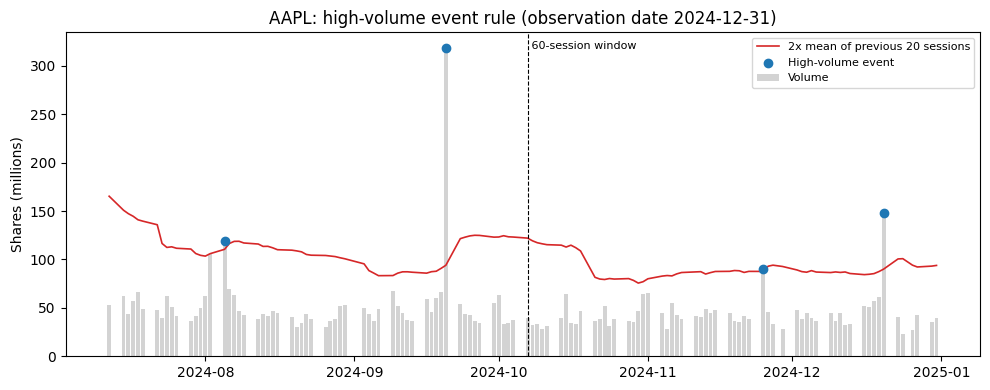

In [12]:
# 1.5 Worked example (default AAPL)
EX = "AAPL" if "AAPL" in vol.columns else vol.columns[0]
ex = pd.DataFrame({"Close": close[EX], "Volume": vol[EX], "mean_prev20": baseline_mean[EX],
                   "threshold_2x": MULT * baseline_mean[EX], "event": events[EX]})
last60 = ex.iloc[-WINDOW:]
ev_table = ex[ex.event].tail(8).copy()
ev_table.to_csv(TAB/f"worked_example_{EX}_events.csv")
print(f"\nWorked example {EX}: obs date {obs_date.date()}")
print(ev_table)
le = ex.index[ex.event].max()
print(f"R = ({obs_date.date()} - {le.date()}) = {R[EX]} calendar days")
print(f"F = {int(F[EX])} events in last {WINDOW} sessions ({last60.index[0].date()} -> {last60.index[-1].date()})")
print(f"M = sum(Close*Volume) over those {WINDOW} sessions = ${M[EX]:,.0f} (= ${M[EX]/1e9:,.1f}bn)")

fig, ax = plt.subplots(figsize=(10, 4))
plot = ex.iloc[-120:]
ax.bar(plot.index, plot.Volume / 1e6, color="lightgrey", label="Volume")
ax.plot(plot.index, plot.threshold_2x / 1e6, color="tab:red", lw=1.2, label="2x mean of previous 20 sessions")
ax.scatter(plot.index[plot.event], plot.Volume[plot.event] / 1e6, color="tab:blue", zorder=3, label="High-volume event")
ax.axvline(last60.index[0], ls="--", color="k", lw=0.8); ax.text(last60.index[0], ax.get_ylim()[1]*0.95, " 60-session window", fontsize=8)
ax.set_ylabel("Shares (millions)"); ax.set_title(f"{EX}: high-volume event rule (observation date {obs_date.date()})"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/f"worked_example_{EX}.png", dpi=200)
if "inline" in plt.get_backend().lower():   # show the figure when running as a notebook
    plt.show()

> **Task 1 · Sanity check**
>
>
>
> **This cell:** Prints features for well-known shares (AAPL, MSFT, NVDA, JNJ, XOM) so the values can be checked by eye. For example, JNJ should have a low beta and NVDA a high one.
>
> **Output:** Printed table only.

In [13]:
# Quick sanity: beta vs sector sanity and known benchmarks
print(feat.loc[[t for t in ["AAPL", "MSFT", "NVDA", "JNJ", "XOM"] if t in feat.index],
               ["mean_weekly_return", "beta", "R", "F", "M_usd"]].round(4))

        mean_weekly_return    beta    R  F         M_usd
ticker                                                  
AAPL                0.0039  1.1748   11  2  6.233034e+11
MSFT                0.0040  1.1286   11  2  5.348982e+11
NVDA                0.0136  2.1260  222  0  1.825337e+12
JNJ                 0.0003  0.3051   11  1  6.839961e+10
XOM                 0.0058  0.5131   11  2  1.010414e+11


---
# TASK 2: Stock segmentation and sensitivity analysis

Output: tables/, figures/, data/processed/cluster_assignments.csv, data/processed/task2_results.json  

Four baseline solutions = 2 feature matrices x 2 algorithms:  
  A = risk-return  [mean weekly return, weekly beta]  
  B = RFM activity [Recency, Frequency, log1p(Monetary)]  
  algorithms: Ward agglomerative, K-means  


> **Task 2 · Configuration**
>
>
>
> **This cell:** Sets seed 42, K-means `n_init=50` and k = 2 to 8. Sets the k-selection rule: highest silhouette with k >= 3 and smallest cluster >= 5% of shares. Includes a figure-saving helper.
>
> **Output:** Nothing saved.

In [14]:
# CONFIG: every tunable choice lives here
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.stats import spearmanr
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42                  # random seed for K-means and anything random
K_RANGE = range(2, 9)      # candidate cluster counts (brief: 2 to 8)
N_INIT = 50                # K-means restarts per fit
N_STABILITY_SEEDS = 10     # seeds used in the K-means stability check

# k-selection rule: highest silhouette among k >= K_MIN_SELECT whose smallest cluster
# holds at least MIN_CLUSTER_SHARE of shares. k = 2 is still reported in every table but
# is not eligible, because a two-way split is a weak segmentation.
K_MIN_SELECT = 3
MIN_CLUSTER_SHARE = 0.05
# After reading the profiles you may overrule the rule, e.g. {"B_ward": 4}. Leave empty
# to use the rule. Any override must be justified in the report.
K_OVERRIDE = {}

LOG_R = False              # False = keep Recency raw (as in the brief); True = log1p(R)

ROOT = Path(".")
PROC, TAB, FIG = ROOT / "data/processed", ROOT / "tables", ROOT / "figures"
for d in (TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = plt.get_cmap("tab10").colors
SOLUTIONS = ["A_ward", "A_kmeans", "B_ward", "B_kmeans"]
results = {}   # numbers collected here are saved to task2_results.json for the report


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200)
    if "inline" in plt.get_backend().lower():   # show the figure when running as a notebook
        plt.show()
    plt.close(fig)

> **Task 2.1 · Feature preparation (common share set)**
>
>
>
> **This cell:** Loads the Task 1 feature table and keeps only shares valid for both risk-return and RFM.
>
> **Output:** Prints the number of shares used in all four solutions.

In [15]:
# 2.1 Load the common share set
feat = pd.read_csv(PROC / "feature_table.csv", index_col="ticker")
common = feat[feat["common_set"]].copy()          # shares valid for BOTH matrices (used everywhere below)
print(f"Common share set: {len(common)} shares (of {len(feat)} in feature table)")
results["n_common"] = int(len(common))

Common share set: 486 shares (of 486 in feature table)


> **Task 2.1 · Feature preparation (matrices, skew, outliers, scaling)**
>
>
>
> **This cell:** Builds A and B, measures skew before and after transformation, applies log1p to M, lists the outliers kept, and fits a separate StandardScaler for each matrix.
>
> **Output:** `tables/t2_skew_outlier_diagnostics.csv`, `tables/t2_outliers_kept.csv`, `figures/f2_1_feature_distributions.png`.

matrix             feature  skew_raw  skew_used  n_abs_z_gt_3  max_abs_z      transform
     A  mean_weekly_return     0.868      0.868           6.0      5.631           none
     A                beta     1.104      1.104           2.0      6.893           none
     B                   R     3.646      3.646          11.0      9.455           none
     B                   F     0.425      0.425           5.0      3.769           none
     B               M_usd    11.684      1.079           7.0      4.848          log1p
     B R (candidate log1p)     3.646      1.583           NaN        NaN candidate only
29 outlier rows saved (outliers are real data and are kept)


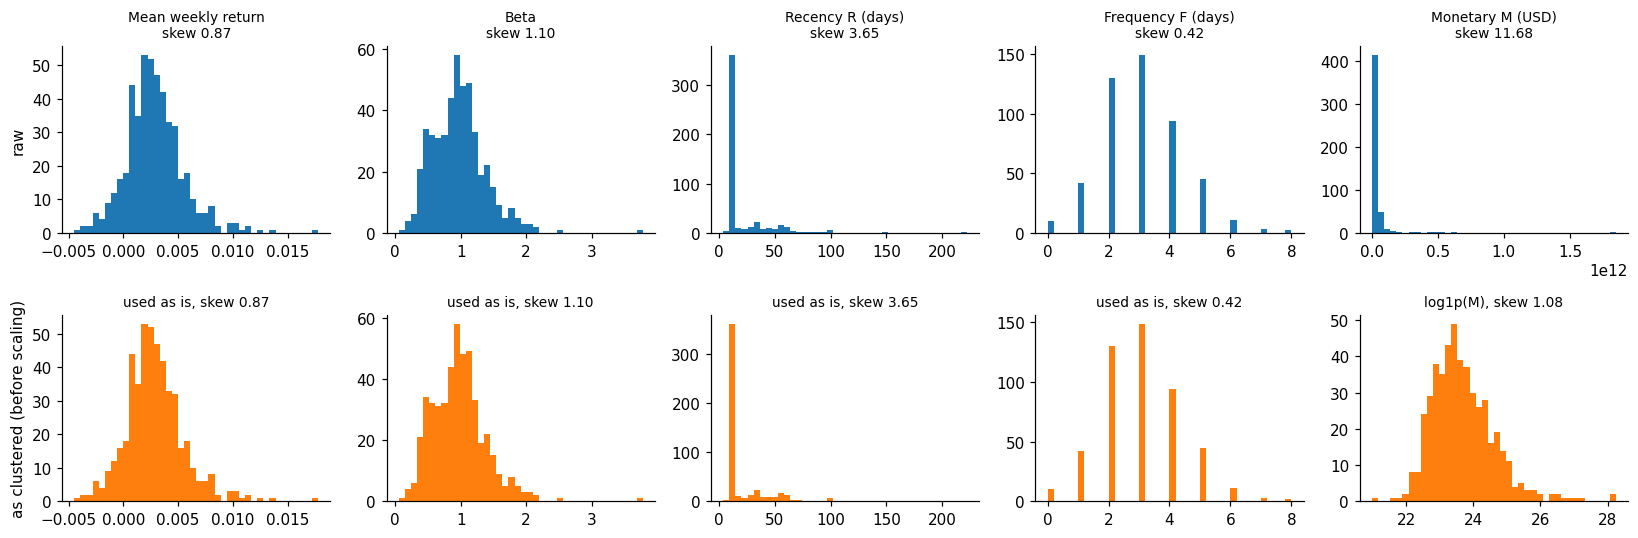

In [16]:
# 2.1 Feature matrices, transformations and scaling
FEATURES = {"A": ["mean_weekly_return", "beta"], "B": ["R", "F", "M_usd"]}


def prepare(name):
    """Return (transformed, standardised, scaler) for matrix 'A' or 'B'.
    Only B is transformed: log1p(Monetary) always, log1p(Recency) only if LOG_R."""
    X = common[FEATURES[name]].copy()
    if name == "B":
        X["M_usd"] = np.log1p(X["M_usd"])
        X = X.rename(columns={"M_usd": "log1p_M"})
        if LOG_R:
            X["R"] = np.log1p(X["R"])
    scaler = StandardScaler()                      # fitted separately per matrix
    Xs = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)
    return X, Xs, scaler


X_raw, X_std = {}, {}
for m in ("A", "B"):
    _, X_std[m], _ = prepare(m)
    X_raw[m] = common[FEATURES[m]]
Xt_B, _, _ = prepare("B")

# --- skew and outlier diagnostics (before vs after transformation)
diag_rows = []
for m in ("A", "B"):
    transformed, standardised, _ = prepare(m)
    for raw_col, new_col in zip(FEATURES[m], transformed.columns):
        z = standardised[new_col]
        diag_rows.append({
            "matrix": m, "feature": raw_col, "skew_raw": common[raw_col].skew(),
            "skew_used": transformed[new_col].skew(), "n_abs_z_gt_3": int((z.abs() > 3).sum()),
            "max_abs_z": z.abs().max(), "transform": "log1p" if new_col != raw_col else "none"})
# extra candidate: what log1p(R) would do (reported, not used unless LOG_R=True)
diag_rows.append({"matrix": "B", "feature": "R (candidate log1p)", "skew_raw": common["R"].skew(),
                  "skew_used": np.log1p(common["R"]).skew(), "n_abs_z_gt_3": np.nan,
                  "max_abs_z": np.nan, "transform": "candidate only"})
skew_table = pd.DataFrame(diag_rows).round(3)
skew_table.to_csv(TAB / "t2_skew_outlier_diagnostics.csv", index=False)
print(skew_table.to_string(index=False))

# list shares that sit more than 3 SD from the mean on any feature (kept, not removed)
outlier_rows = []
for m in ("A", "B"):
    z = X_std[m]
    for t in z.index[(z.abs() > 3).any(axis=1)]:
        outlier_rows.append({"matrix": m, "ticker": t, "company": common.loc[t, "company"],
                             **{c: round(z.loc[t, c], 2) for c in z.columns}})
pd.DataFrame(outlier_rows).to_csv(TAB / "t2_outliers_kept.csv", index=False)
print(f"{len(outlier_rows)} outlier rows saved (outliers are real data and are kept)")

# --- histograms: raw vs used
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
labels_raw = {"mean_weekly_return": "Mean weekly return", "beta": "Beta", "R": "Recency R (days)",
              "F": "Frequency F (days)", "M_usd": "Monetary M (USD)"}
used = {"mean_weekly_return": common["mean_weekly_return"], "beta": common["beta"],
        "R": Xt_B["R"], "F": Xt_B["F"], "M_usd": Xt_B["log1p_M"]}
for j, col in enumerate(labels_raw):
    axes[0, j].hist(common[col], bins=40, color=COLORS[0])
    axes[0, j].set_title(f"{labels_raw[col]}\nskew {common[col].skew():.2f}", fontsize=9)
    axes[1, j].hist(used[col], bins=40, color=COLORS[1])
    tag = "log1p(M)" if col == "M_usd" else ("log1p(R)" if (col == "R" and LOG_R) else "used as is")
    axes[1, j].set_title(f"{tag}, skew {used[col].skew():.2f}", fontsize=9)
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("as clustered (before scaling)")
save_fig(fig, "f2_1_feature_distributions.png")

> **Task 2.2 / 2.3 · Helpers**
>
>
>
> **This cell:** Functions that fit Ward (Euclidean) or K-means, then return labels, silhouette, inertia and cluster sizes, and build original-unit profiles.
>
> **Output:** Nothing saved.

In [17]:
# Helper functions shared by Ward and K-means
def fit_labels(algo, X, k):
    """Cluster rows of X into k groups; return (labels, inertia). Inertia = within-cluster sum of squares."""
    if algo == "ward":
        labels = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
        return labels, within_ss(X, labels)
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
    return km.labels_, km.inertia_


def within_ss(X, labels):
    """Within-cluster sum of squared distances to each cluster centroid."""
    X = np.asarray(X)
    return float(sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels)))


def relabel(labels, order_by):
    """Renumber clusters 0..k-1 so cluster 0 has the LOWEST mean of `order_by`.
    Cluster numbers are arbitrary in clustering; this just makes tables/plots comparable.
    (The adjusted Rand index ignores numbering, so it is unaffected.)"""
    means = pd.Series(np.asarray(order_by)).groupby(labels).mean().sort_values()
    mapping = {old: new for new, old in enumerate(means.index)}
    return np.array([mapping[x] for x in labels])


def profile_table(labels):
    """Cluster profile in ORIGINAL units (not standardised)."""
    df = common.assign(cluster=labels)
    g = df.groupby("cluster")
    out = pd.DataFrame({
        "n_shares": g.size(),
        "share_pct": (g.size() / len(df) * 100),
        "return_mean_pct_wk": g["mean_weekly_return"].mean() * 100,
        "return_median_pct_wk": g["mean_weekly_return"].median() * 100,
        "beta_mean": g["beta"].mean(), "beta_median": g["beta"].median(),
        "R_mean_days": g["R"].mean(), "R_median_days": g["R"].median(),
        "F_mean": g["F"].mean(), "F_median": g["F"].median(),
        "M_median_usd_bn": g["M_usd"].median() / 1e9, "M_mean_usd_bn": g["M_usd"].mean() / 1e9,
    })
    return out.round(3)

> **Task 2.2 + 2.3 · Choosing the number of clusters** ·
>
>
>
> **This cell:** Fits all 28 combinations (2 matrices x 2 algorithms x 7 values of k), records the diagnostics and applies the selection rule from CONFIG.
>
> **Output:** `tables/t2_k_diagnostics_all.csv`, `tables/t2_selected_k.csv`, `figures/f2_2_k_diagnostics.png`.

matrix   algo  k  silhouette  inertia  min_size  min_share                    sizes
     A   ward  2       0.339  705.810        92      0.189                   394/92
     A   ward  3       0.274  529.038        92      0.189               230/164/92
     A   ward  4       0.282  428.069        48      0.099            182/164/92/48
     A   ward  5       0.304  347.817        48      0.099          182/98/92/66/48
     A   ward  6       0.320  280.521         5      0.010        182/98/87/66/48/5
     A   ward  7       0.324  245.730         5      0.010     160/98/87/66/48/22/5
     A   ward  8       0.321  211.216         5      0.010  160/98/66/56/48/31/22/5
     A kmeans  2       0.387  621.634       143      0.294                  343/143
     A kmeans  3       0.329  461.179       119      0.245              202/165/119
     A kmeans  4       0.327  371.577        40      0.082           160/154/132/40
     A kmeans  5       0.341  309.613        27      0.056        166/131/11

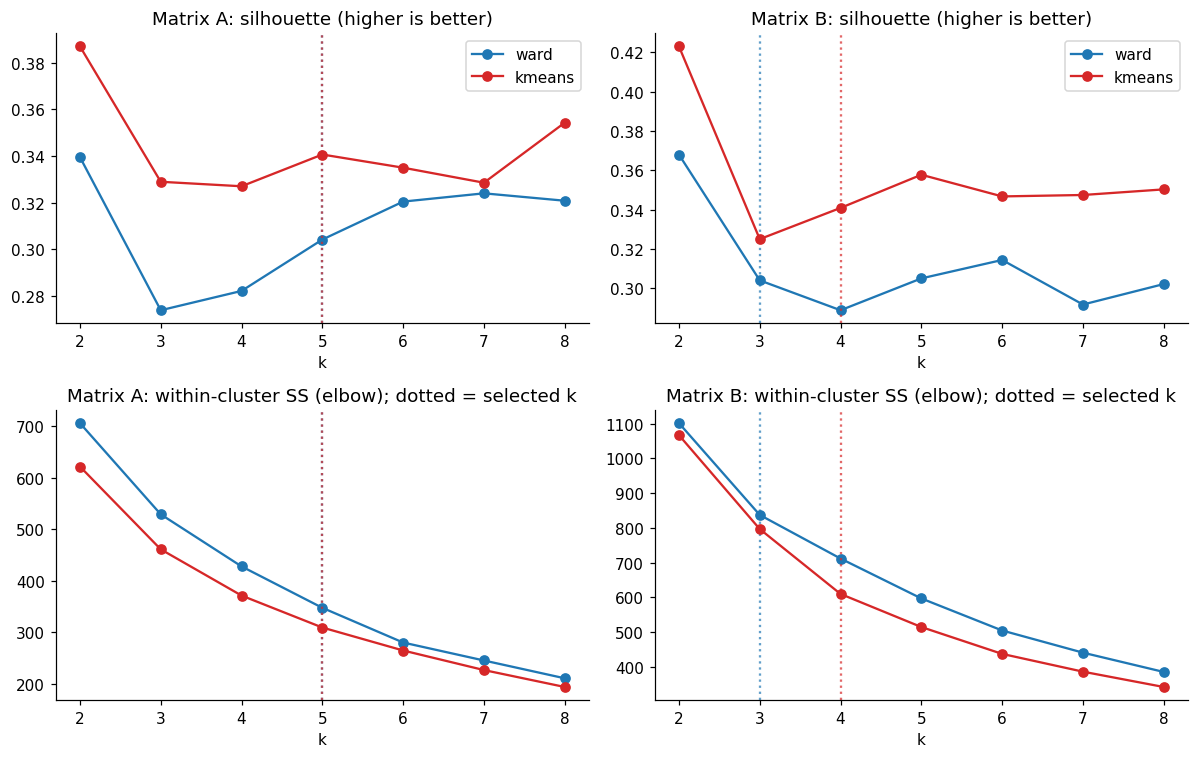

In [18]:
# 2.2 + 2.3 Diagnostics for k = 2..8 (both algorithms, both matrices)
diag = []
for m in ("A", "B"):
    for algo in ("ward", "kmeans"):
        for k in K_RANGE:
            labels, inertia = fit_labels(algo, X_std[m], k)
            sizes = np.bincount(labels)
            diag.append({"matrix": m, "algo": algo, "k": k,
                         "silhouette": silhouette_score(X_std[m], labels),
                         "inertia": inertia, "min_size": sizes.min(),
                         "min_share": sizes.min() / len(labels),
                         "sizes": "/".join(map(str, sorted(sizes, reverse=True)))})
diag = pd.DataFrame(diag)
diag.round(4).to_csv(TAB / "t2_k_diagnostics_all.csv", index=False)
print(diag.round(3).to_string(index=False))


def choose_k(matrix, algo):
    """Apply the k-selection rule described in CONFIG; return (k, how_chosen)."""
    key = f"{matrix}_{algo}"
    if key in K_OVERRIDE:
        return K_OVERRIDE[key], "manual override"
    d = diag[(diag.matrix == matrix) & (diag.algo == algo) & (diag.k >= K_MIN_SELECT)]
    eligible = d[d.min_share >= MIN_CLUSTER_SHARE]
    how = "max silhouette, k>=3, smallest cluster >=5%"
    if eligible.empty:
        eligible, how = d, "max silhouette, k>=3 (no k met the 5% size rule)"
    return int(eligible.loc[eligible["silhouette"].idxmax(), "k"]), how


chosen = {s: choose_k(*s.split("_")) for s in SOLUTIONS}
print("\nSelected k:", {s: v[0] for s, v in chosen.items()})
results["selected_k"] = {s: {"k": v[0], "rule": v[1]} for s, v in chosen.items()}
pd.DataFrame([{"solution": s, "k": v[0], "rule": v[1]} for s, v in chosen.items()]).to_csv(
    TAB / "t2_selected_k.csv", index=False)

# --- silhouette and inertia charts (one panel per matrix)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, m in enumerate(("A", "B")):
    for algo, col in (("ward", COLORS[0]), ("kmeans", COLORS[3])):
        d = diag[(diag.matrix == m) & (diag.algo == algo)]
        axes[0, j].plot(d.k, d.silhouette, "o-", color=col, label=algo)
        axes[1, j].plot(d.k, d.inertia, "o-", color=col, label=algo)
        axes[0, j].axvline(chosen[f"{m}_{algo}"][0], color=col, ls=":", alpha=0.7)
        axes[1, j].axvline(chosen[f"{m}_{algo}"][0], color=col, ls=":", alpha=0.7)
    axes[0, j].set_title(f"Matrix {m}: silhouette (higher is better)"); axes[0, j].set_xlabel("k")
    axes[1, j].set_title(f"Matrix {m}: within-cluster SS (elbow); dotted = selected k"); axes[1, j].set_xlabel("k")
    axes[0, j].legend()
save_fig(fig, "f2_2_k_diagnostics.png")

> **Task 2.2 · Agglomerative clustering: dendrograms** · *9 marks*
>
>
>
> **This cell:** Draws a truncated Ward dendrogram for each matrix and tabulates the last merge heights as supporting evidence for k.
>
> **Output:** `figures/f2_3_dendrogram_A.png`, `figures/f2_3_dendrogram_B.png`, `tables/t2_ward_last_merges_*.csv`.

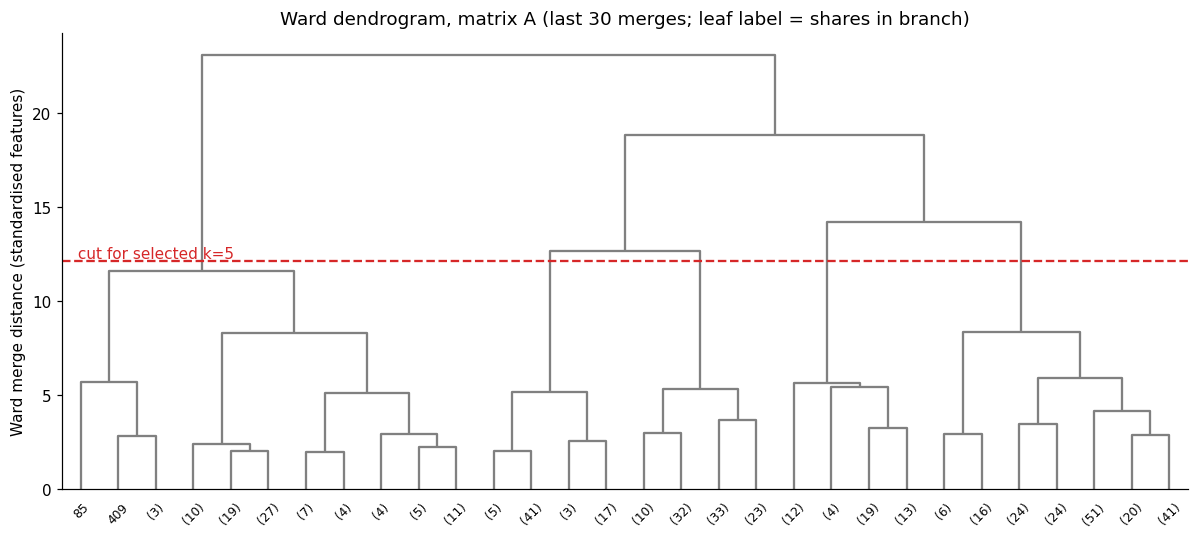

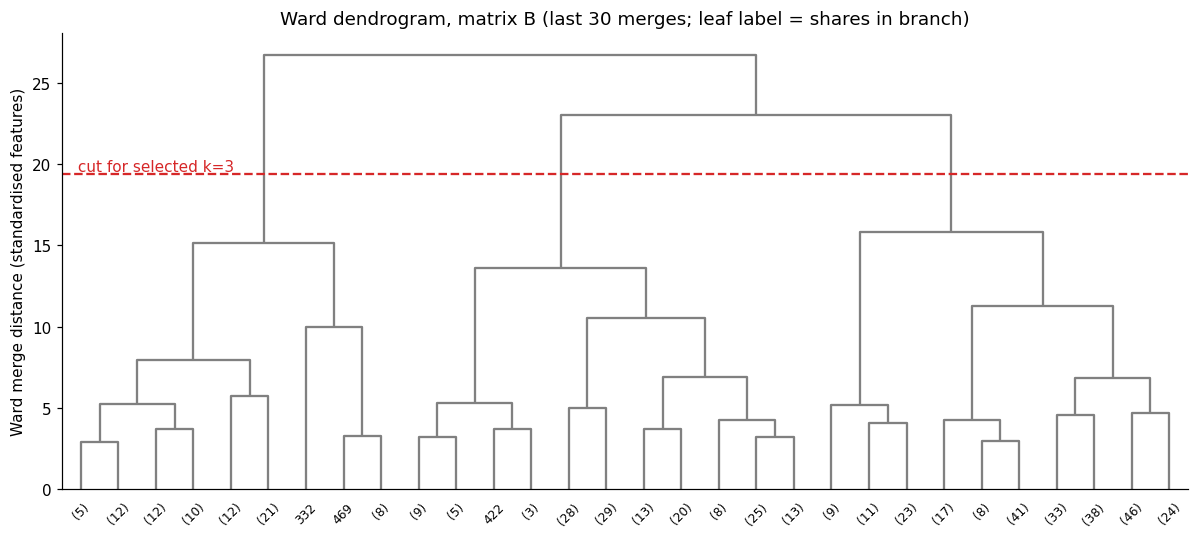

In [19]:
# 2.2 Ward dendrograms (one per matrix) + merge-height evidence
Z = {}
for m in ("A", "B"):
    Z[m] = linkage(X_std[m], method="ward", metric="euclidean")
    k = chosen[f"{m}_ward"][0]
    # sanity: scipy's tree cut must agree with sklearn's Ward at the same k
    ari = adjusted_rand_score(fcluster(Z[m], k, "maxclust"), fit_labels("ward", X_std[m], k)[0])
    assert ari > 0.99, f"scipy and sklearn Ward disagree for matrix {m} (ARI={ari:.3f})"

    heights = Z[m][:, 2]
    cut = (heights[-k] + heights[-(k - 1)]) / 2          # horizontal line giving exactly k clusters
    fig, ax = plt.subplots(figsize=(11, 5))
    dendrogram(Z[m], truncate_mode="lastp", p=30, ax=ax, color_threshold=0,
               above_threshold_color="grey", leaf_font_size=8, show_leaf_counts=True)
    ax.axhline(cut, color="tab:red", ls="--")
    ax.text(0.01, cut, f" cut for selected k={k}", color="tab:red", va="bottom", transform=ax.get_yaxis_transform())
    ax.set_title(f"Ward dendrogram, matrix {m} (last 30 merges; leaf label = shares in branch)")
    ax.set_ylabel("Ward merge distance (standardised features)")
    save_fig(fig, f"f2_3_dendrogram_{m}.png")

    # last 10 merges: a big jump in height means two well-separated groups are being joined
    last = pd.DataFrame({"merges_left": np.arange(10, 0, -1) + 0,
                         "clusters_after_merge": np.arange(10, 0, -1),
                         "height": heights[-10:]})
    last["jump_from_previous"] = last["height"].diff()
    last.round(3).to_csv(TAB / f"t2_ward_last_merges_{m}.csv", index=False)

> **Task 2.3 · K-means clustering: initialisation**
>
>
>
> **This cell:** Compares `n_init=50` with 30 single-start runs (spread of inertia), and refits with other seeds to measure label stability (ARI).
>
> **Output:** `tables/t2_kmeans_stability.csv`.

In [20]:
# 2.3 K-means: initialisation sensitivity and seed stability at the selected k
km_rows = []
for m in ("A", "B"):
    k = chosen[f"{m}_kmeans"][0]
    base = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_std[m])
    # (a) one random start vs fifty: how much does a single start risk a bad local optimum?
    single = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(X_std[m]).inertia_ for s in range(30)]
    # (b) do different seeds (each with 50 starts) give the same partition?
    aris = [adjusted_rand_score(base.labels_, KMeans(n_clusters=k, n_init=N_INIT, random_state=s)
                                .fit_predict(X_std[m])) for s in range(N_STABILITY_SEEDS)]
    km_rows.append({"matrix": m, "k": k, "inertia_n_init50": base.inertia_,
                    "inertia_single_start_min": min(single), "inertia_single_start_max": max(single),
                    "share_single_starts_worse_than_base": np.mean(np.array(single) > base.inertia_ * 1.0001),
                    "ARI_vs_base_min": min(aris), "ARI_vs_base_mean": float(np.mean(aris))})
km_stab = pd.DataFrame(km_rows).round(4)
km_stab.to_csv(TAB / "t2_kmeans_stability.csv", index=False)
print(km_stab.to_string(index=False))

matrix  k  inertia_n_init50  inertia_single_start_min  inertia_single_start_max  share_single_starts_worse_than_base  ARI_vs_base_min  ARI_vs_base_mean
     A  5          309.6130                  309.8001                  364.5082                                  1.0           0.9104            0.9402
     B  4          609.8325                  609.8325                  790.0793                                  0.6           0.9939            0.9982


> **Task 2.4 · Cluster profiles in original units** · *5 marks*
>
>
>
> **This cell:** Fits the four final solutions at the selected k and renumbers clusters in a consistent order. Builds profiles: return %/week, beta, R days, F count, M in $bn, and size.
>
> **Output:** `tables/t2_profile_A_ward.csv`, `t2_profile_A_kmeans.csv`, `t2_profile_B_ward.csv`, `t2_profile_B_kmeans.csv`.

In [21]:
# 2.4 Final labels for the four baseline solutions (ordered for readability)
order_by = {"A": common["beta"], "B": np.log1p(common["M_usd"])}   # cluster 0 = lowest beta / lowest traded value
labels_final = {}
for s in SOLUTIONS:
    m, algo = s.split("_")
    raw_labels, _ = fit_labels(algo, X_std[m], chosen[s][0])
    labels_final[s] = relabel(raw_labels, order_by[m])

profiles = {}
for s in SOLUTIONS:
    profiles[s] = profile_table(labels_final[s])
    profiles[s].to_csv(TAB / f"t2_profile_{s}.csv")
    print(f"\n--- Profile {s} (k={chosen[s][0]}), original units ---")
    print(profiles[s].to_string())


--- Profile A_ward (k=5), original units ---
         n_shares  share_pct  return_mean_pct_wk  return_median_pct_wk  beta_mean  beta_median  R_mean_days  R_median_days  F_mean  F_median  M_median_usd_bn  M_mean_usd_bn
cluster                                                                                                                                                                     
0              66     13.580               0.088                 0.113      0.439        0.449       26.197           11.0   2.894       3.0           17.701         25.888
1              98     20.165               0.422                 0.392      0.710        0.666       16.908           11.0   2.704       3.0           17.649         24.691
2             182     37.449               0.132                 0.166      0.973        0.964       17.714           11.0   3.011       3.0           12.985         19.788
3              92     18.930               0.632                 0.550      1.298        

> **Task 2.4 · Labelled 2D visualisation**
>
>
>
> **This cell:** Matrix A is already 2D, so it is plotted directly. Matrix B (3 features) is projected with PCA, and the variance explained and loadings are reported.
>
> **Output:** `figures/f2_4_scatter_A.png`, `figures/f2_4_scatter_B_pca.png`, `tables/t2_pca_loadings_B.csv`.

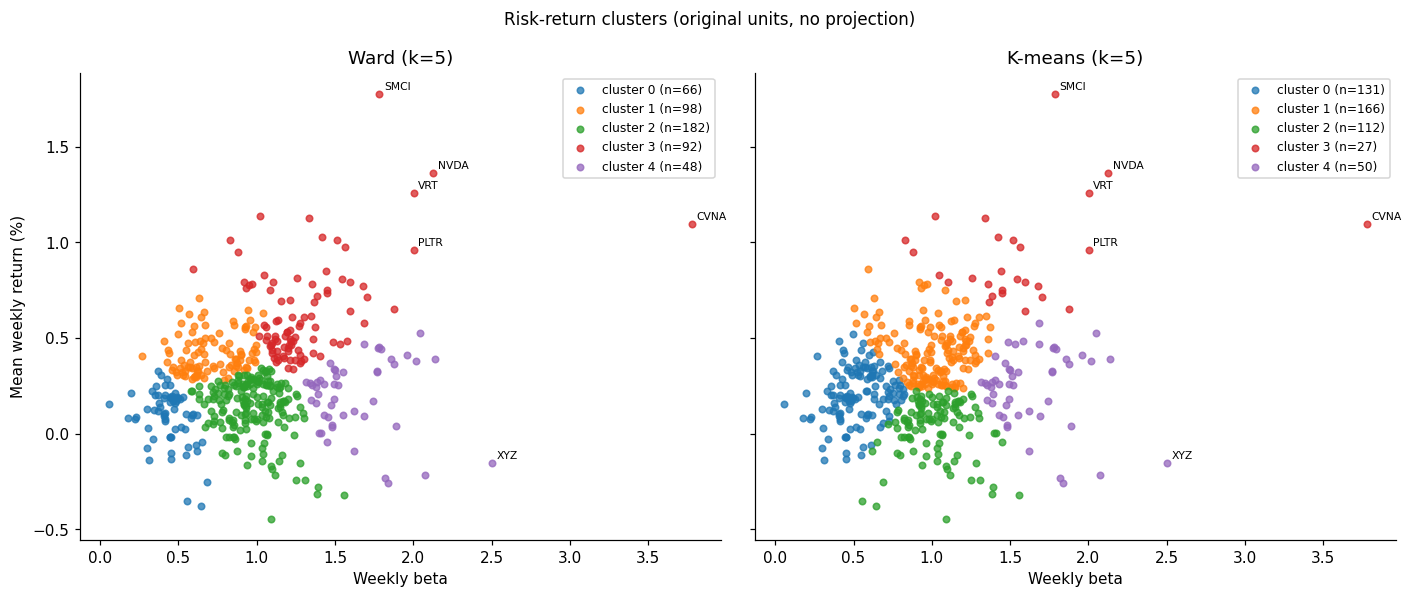


PCA loadings (matrix B):
                             PC1    PC2
R                         0.711  0.023
F                        -0.650  0.402
log1p_M                   0.268  0.915
explained_variance_ratio  0.458  0.336


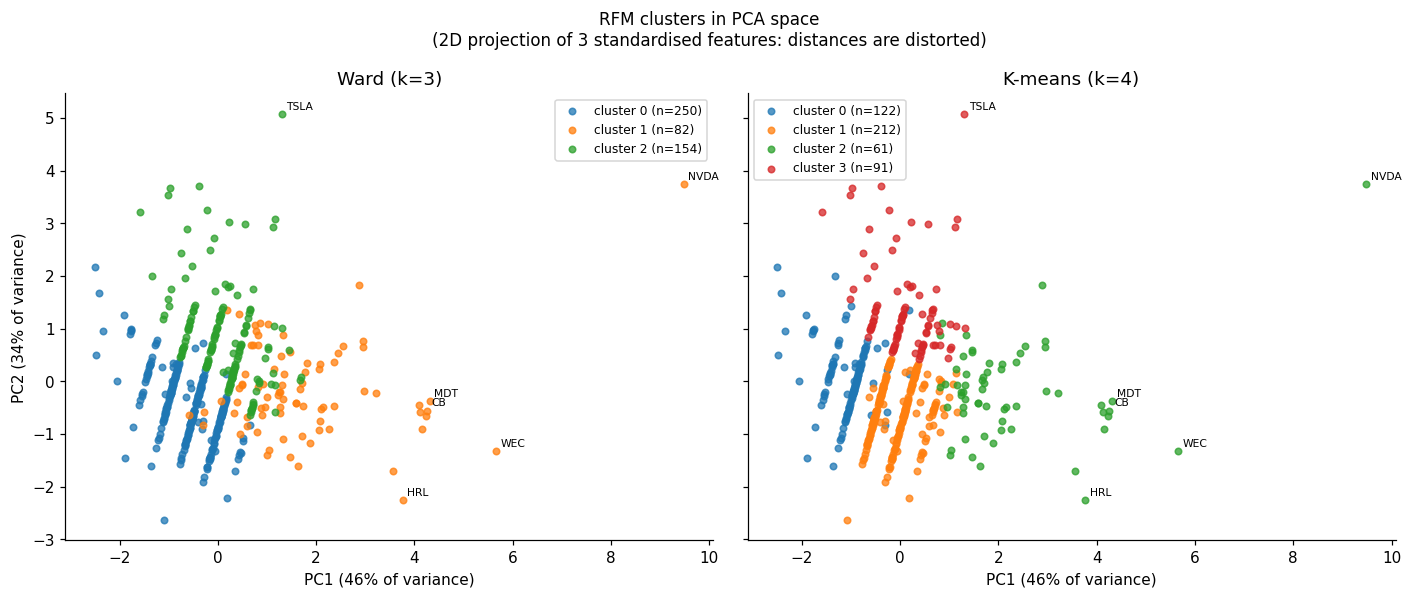

In [22]:
# 2.4 Labelled 2D visualisations
def flag_extremes(Xs2d, n=6):
    """Indices of the n points farthest from the centre of the 2D cloud (to annotate)."""
    d = np.sqrt((Xs2d ** 2).sum(axis=1))
    return np.argsort(d)[-n:]


def scatter_pair(coords, xlabel, ylabel, fname, title, extra_note=""):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
    for ax, algo in zip(axes, ("ward", "kmeans")):
        s = f"{matrix_now}_{algo}"
        lab = labels_final[s]
        for c in np.unique(lab):
            idx = lab == c
            ax.scatter(coords[idx, 0], coords[idx, 1], s=18, color=COLORS[c % 10], alpha=0.75,
                       label=f"cluster {c} (n={idx.sum()})")
        for i in flag_extremes(coords_std_now):
            ax.annotate(common.index[i], (coords[i, 0], coords[i, 1]), fontsize=7, xytext=(3, 3),
                        textcoords="offset points")
        ax.set_title(f"{'Ward' if algo == 'ward' else 'K-means'} (k={chosen[s][0]})"); ax.set_xlabel(xlabel)
        ax.legend(fontsize=8)
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title + extra_note, fontsize=11)
    save_fig(fig, fname)


# Matrix A has exactly 2 features, so plot them directly: no dimension reduction needed.
matrix_now = "A"
coords_std_now = X_std["A"].values
scatter_pair(np.c_[common["beta"], common["mean_weekly_return"] * 100], "Weekly beta",
             "Mean weekly return (%)", "f2_4_scatter_A.png", "Risk-return clusters (original units, no projection)")

# Matrix B has 3 features: project to 2D with PCA on the standardised features.
pca = PCA(n_components=2, random_state=SEED).fit(X_std["B"])
pc = pca.transform(X_std["B"])
loadings = pd.DataFrame(pca.components_.T, index=X_std["B"].columns, columns=["PC1", "PC2"]).round(3)
loadings.loc["explained_variance_ratio"] = pca.explained_variance_ratio_.round(3)
loadings.to_csv(TAB / "t2_pca_loadings_B.csv")
print("\nPCA loadings (matrix B):\n", loadings)
results["pca_B_explained_variance"] = [float(v) for v in pca.explained_variance_ratio_]
matrix_now = "B"
coords_std_now = pc
scatter_pair(pc, f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
             f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)", "f2_4_scatter_B_pca.png",
             "RFM clusters in PCA space", "\n(2D projection of 3 standardised features: distances are distorted)")

> **Task 2.4 · Algorithm comparison**
>
>
>
> **This cell:** Adjusted Rand index and crosstabs between Ward and K-means for each matrix. ARI ignores arbitrary cluster numbering.
>
> **Output:** `tables/t2_algorithm_comparison.csv`, `tables/t2_crosstab_ward_vs_kmeans_*.csv`, `figures/f2_5_ward_vs_kmeans_crosstab.png`.

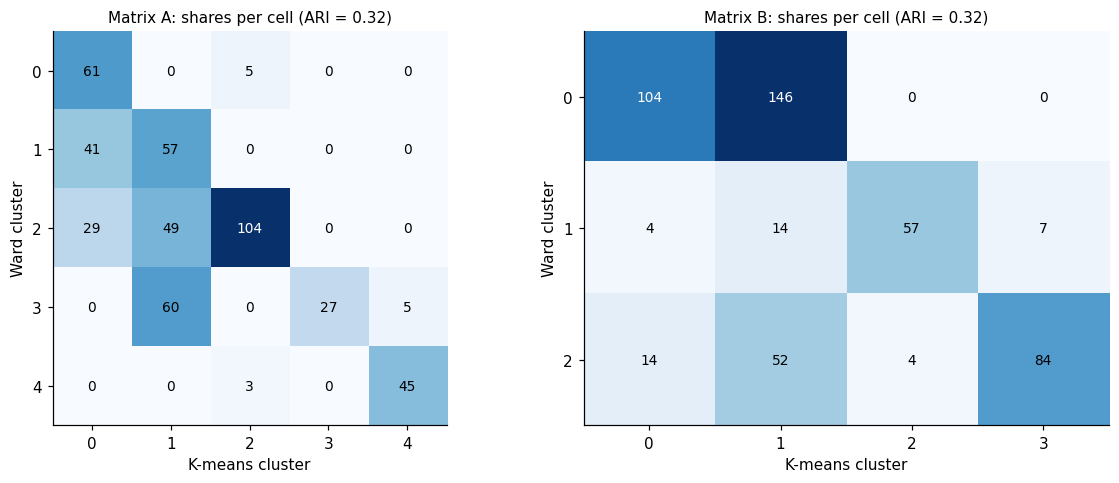


 matrix  k_ward  k_kmeans  ARI_ward_vs_kmeans  silhouette_ward  silhouette_kmeans
     A       5         5              0.3183           0.3041             0.3406
     B       3         4              0.3180           0.3040             0.3409


In [23]:
# 2.4 Algorithm comparison on the same shares: ARI + crosstab heatmaps
def heatmap(ax, mat, xlabels, ylabels, title, cmap="Blues"):
    ax.imshow(mat, cmap=cmap)
    ax.set_xticks(range(len(xlabels)), xlabels); ax.set_yticks(range(len(ylabels)), ylabels)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.0f}" if float(mat[i, j]).is_integer() else f"{mat[i, j]:.2f}",
                    ha="center", va="center", fontsize=9,
                    color="white" if mat[i, j] > mat.max() * 0.6 else "black")
    ax.set_title(title, fontsize=10)


comparison = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, m in zip(axes, ("A", "B")):
    a, b = labels_final[f"{m}_ward"], labels_final[f"{m}_kmeans"]
    ct = pd.crosstab(pd.Series(a, name="Ward cluster"), pd.Series(b, name="K-means cluster"))
    ct.to_csv(TAB / f"t2_crosstab_ward_vs_kmeans_{m}.csv")
    ari = adjusted_rand_score(a, b)
    comparison.append({"matrix": m, "k_ward": chosen[f"{m}_ward"][0], "k_kmeans": chosen[f"{m}_kmeans"][0],
                       "ARI_ward_vs_kmeans": ari,
                       "silhouette_ward": silhouette_score(X_std[m], a),
                       "silhouette_kmeans": silhouette_score(X_std[m], b)})
    heatmap(ax, ct.values, ct.columns, ct.index, f"Matrix {m}: shares per cell (ARI = {ari:.2f})")
    ax.set_xlabel("K-means cluster"); ax.set_ylabel("Ward cluster")
save_fig(fig, "f2_5_ward_vs_kmeans_crosstab.png")
comparison = pd.DataFrame(comparison).round(4)
comparison.to_csv(TAB / "t2_algorithm_comparison.csv", index=False)
print("\n", comparison.to_string(index=False))
results["ari_ward_vs_kmeans"] = {r.matrix: float(r.ARI_ward_vs_kmeans) for r in comparison.itertuples()}

> **Task 2.5.1 · Correlation analysis**
>
>
>
> **This cell:** Pearson and Spearman correlation matrices, with a heatmap.
>
> **Output:** `tables/t2_corr_pearson.csv`, `tables/t2_corr_spearman.csv`, `figures/f2_6_correlation_heatmap.png`.


Pearson:
              R      F  log1p_M
R        1.000 -0.346    0.152
F       -0.346  1.000    0.013
log1p_M  0.152  0.013    1.000 
Spearman:
              R      F  log1p_M
R        1.000 -0.196    0.137
F       -0.196  1.000   -0.048
log1p_M  0.137 -0.048    1.000
Share of variance on PC1 of (R, F, log1p M): 45.79%; eigenvalues [1.374 1.009 0.617]


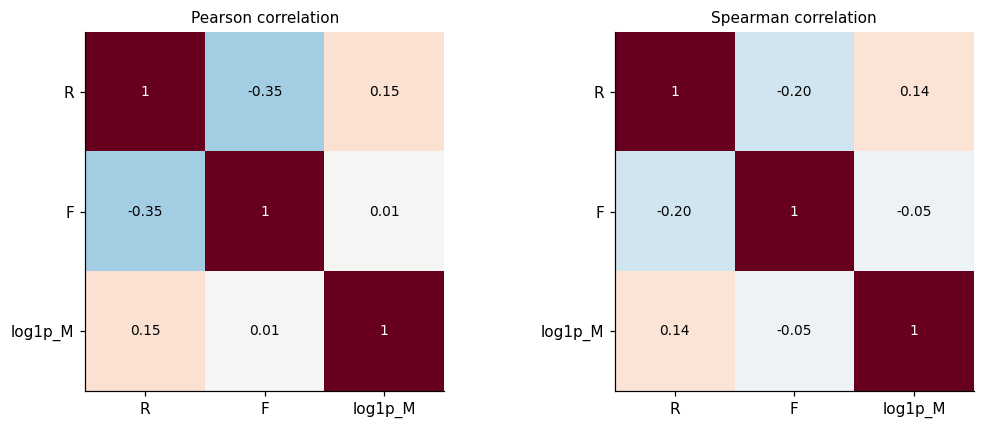

In [24]:
# 2.5.1 Correlation analysis among R, F and log1p(M)
corr_in = pd.DataFrame({"R": common["R"], "F": common["F"], "log1p_M": np.log1p(common["M_usd"])})
pearson = corr_in.corr(method="pearson").round(3)
spearman = corr_in.corr(method="spearman").round(3)
pearson.to_csv(TAB / "t2_corr_pearson.csv"); spearman.to_csv(TAB / "t2_corr_spearman.csv")
print("\nPearson:\n", pearson, "\nSpearman:\n", spearman)

# How much of the total standardised variance lies along ONE shared direction (PC1)?
eig = np.sort(np.linalg.eigvalsh(corr_in.corr().values))[::-1]
pc1_share = float(eig[0] / eig.sum())
print(f"Share of variance on PC1 of (R, F, log1p M): {pc1_share:.2%}; eigenvalues {eig.round(3)}")
results["corr_pearson"] = pearson.to_dict()
results["corr_spearman"] = spearman.to_dict()
results["pc1_share_B"] = pc1_share

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, cm) in zip(axes, (("Pearson", pearson), ("Spearman", spearman))):
    heatmap(ax, cm.values, cm.columns, cm.index, f"{name} correlation", cmap="RdBu_r")
    ax.images[0].set_clim(-1, 1)
save_fig(fig, "f2_6_correlation_heatmap.png")

> **Task 2.5.2 · Removal of Monetary**
>
>
>
> **This cell:** Refits Ward on standardised [R, F], computes ARI against the full RFM solution with a crosstab, and compares M (traded value) per cluster under both solutions.
>
> **Output:** `tables/t2_crosstab_full_vs_RF.csv`, `tables/t2_monetary_removal_profiles.csv`, `figures/f2_7_monetary_removal.png`.


Traded value (M) profiles by cluster:
          solution cluster   n  M_median_usd_bn  M_mean_usd_bn  M_q25_usd_bn  M_q75_usd_bn  R_median  F_median
full R,F,log1p(M)       0 250           11.178         11.764         7.902        14.917      11.0       3.0
full R,F,log1p(M)       1  82           17.849         47.159        13.021        32.502      54.5       2.0
full R,F,log1p(M)       2 154           39.695         80.145        28.223        68.392      11.0       3.0
full R,F,log1p(M)     ALL 486           16.684         39.404        10.195        32.277      11.0       3.0
         R,F only       0 272           14.855         39.401         9.407        30.145      11.0       4.0
         R,F only       1 125           17.699         34.338        10.516        31.804      11.0       2.0
         R,F only       2  89           20.848         46.530        13.738        33.246      54.0       2.0
         R,F only     ALL 486           16.684         39.404        10.195     

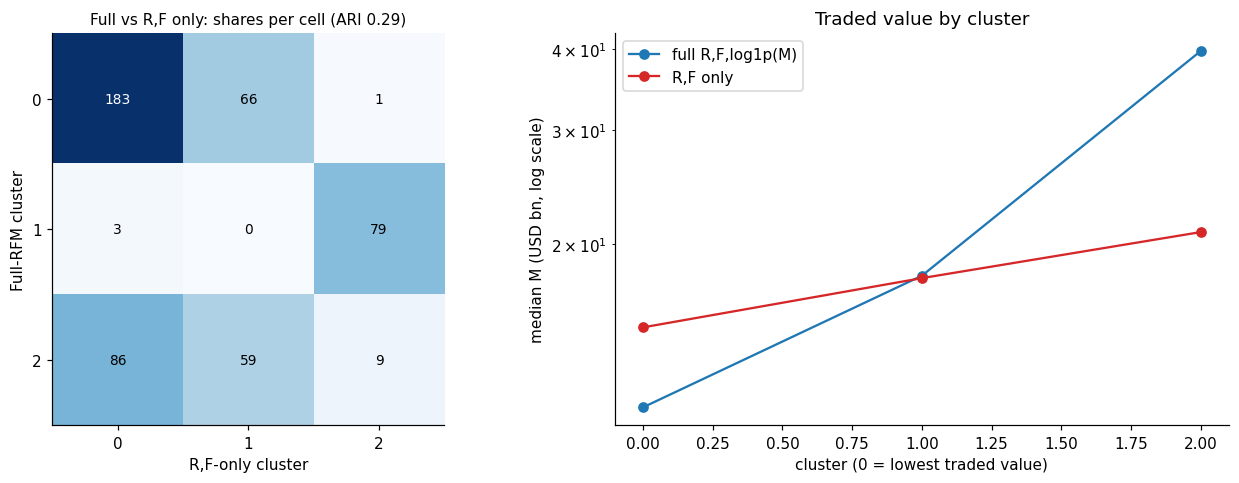

In [25]:
# 2.5.2 Remove Monetary: Ward on R and F only (same shares, same k, scaler refitted)
k_full = chosen["B_ward"][0]
Xrf = pd.DataFrame(StandardScaler().fit_transform(common[["R", "F"]]), index=common.index, columns=["R", "F"])
lab_rf_raw, _ = fit_labels("ward", Xrf, k_full)
lab_full = labels_final["B_ward"]                                # full R+F+log1p(M) Ward solution
lab_rf = relabel(lab_rf_raw, np.log1p(common["M_usd"]))          # ordered by traded value for readability
ari_rf = adjusted_rand_score(lab_full, lab_rf)
sil_rf = silhouette_score(Xrf, lab_rf)

ct_rf = pd.crosstab(pd.Series(lab_full, name="Full R,F,logM"), pd.Series(lab_rf, name="R,F only"))
ct_rf.to_csv(TAB / "t2_crosstab_full_vs_RF.csv")


def eta_squared(values, labels):
    """Share of the variance of `values` explained by cluster membership (0 to 1)."""
    v = np.asarray(values); lab = np.asarray(labels)
    ss_total = ((v - v.mean()) ** 2).sum()
    ss_between = sum((lab == c).sum() * (v[lab == c].mean() - v.mean()) ** 2 for c in np.unique(lab))
    return float(ss_between / ss_total)


logM = np.log1p(common["M_usd"])
m_profile = []
for name, lab in (("full R,F,log1p(M)", lab_full), ("R,F only", lab_rf)):
    df = common.assign(cluster=lab)
    for c, g in df.groupby("cluster"):
        m_profile.append({"solution": name, "cluster": c, "n": len(g),
                          "M_median_usd_bn": g.M_usd.median() / 1e9, "M_mean_usd_bn": g.M_usd.mean() / 1e9,
                          "M_q25_usd_bn": g.M_usd.quantile(.25) / 1e9, "M_q75_usd_bn": g.M_usd.quantile(.75) / 1e9,
                          "R_median": g.R.median(), "F_median": g.F.median()})
    m_profile.append({"solution": name, "cluster": "ALL", "n": len(df), "M_median_usd_bn": df.M_usd.median() / 1e9,
                      "M_mean_usd_bn": df.M_usd.mean() / 1e9, "M_q25_usd_bn": df.M_usd.quantile(.25) / 1e9,
                      "M_q75_usd_bn": df.M_usd.quantile(.75) / 1e9, "R_median": df.R.median(), "F_median": df.F.median()})
m_profile = pd.DataFrame(m_profile).round(3)
m_profile.to_csv(TAB / "t2_monetary_removal_profiles.csv", index=False)
print("\nTraded value (M) profiles by cluster:\n", m_profile.to_string(index=False))

eta_full, eta_rf = eta_squared(logM, lab_full), eta_squared(logM, lab_rf)
print(f"\nARI(full vs R,F only) = {ari_rf:.3f} | eta^2 of log1p(M): full {eta_full:.3f}, R,F only {eta_rf:.3f}")
print(ct_rf)

# robustness extra: does using log1p(R) instead of raw R change the selected Ward RFM solution?
Xalt, _, _ = prepare("B")
Xalt = Xalt.copy(); Xalt["R"] = np.log1p(common["R"]) if not LOG_R else common["R"]
Xalt = pd.DataFrame(StandardScaler().fit_transform(Xalt), index=common.index, columns=Xalt.columns)
ari_logR = adjusted_rand_score(lab_full, relabel(fit_labels("ward", Xalt, k_full)[0], logM))
print(f"Robustness: ARI between current RFM Ward and the version with the other R treatment = {ari_logR:.3f}")

results["monetary_removal"] = {"k": k_full, "ARI_full_vs_RF": ari_rf, "eta2_logM_full": eta_full,
                               "eta2_logM_RF_only": eta_rf, "silhouette_RF_only": float(sil_rf),
                               "silhouette_full": float(silhouette_score(X_std["B"], lab_full)),
                               "ARI_alt_R_treatment": float(ari_logR), "LOG_R_used": LOG_R}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
heatmap(axes[0], ct_rf.values, ct_rf.columns, ct_rf.index, f"Full vs R,F only: shares per cell (ARI {ari_rf:.2f})")
axes[0].set_xlabel("R,F-only cluster"); axes[0].set_ylabel("Full-RFM cluster")
for name, lab, col in (("full R,F,log1p(M)", lab_full, COLORS[0]), ("R,F only", lab_rf, COLORS[3])):
    med = common.assign(c=lab).groupby("c").M_usd.median() / 1e9
    axes[1].plot(med.index, med.values, "o-", color=col, label=name)
axes[1].set_yscale("log"); axes[1].set_xlabel("cluster (0 = lowest traded value)")
axes[1].set_ylabel("median M (USD bn, log scale)"); axes[1].legend(); axes[1].set_title("Traded value by cluster")
save_fig(fig, "f2_7_monetary_removal.png")

> **Task 2 · Deliverable: cluster assignments**
>
>
>
> **This cell:** Saves every share's cluster in all solutions (including R+F-only) and a JSON of the key results.
>
> **Output:** `data/processed/cluster_assignments.csv`, `feature_table_with_clusters.csv`, `task2_results.json`.

In [26]:
# Save assignments and results for Task 3 / report
assign = pd.DataFrame({s: labels_final[s] for s in SOLUTIONS}, index=common.index)
assign["B_ward_RF_only"] = lab_rf
assign.index.name = "ticker"
assign.to_csv(PROC / "cluster_assignments.csv")
full = feat.join(assign)                              # feature table + all assignments (submission checklist item)
full.to_csv(PROC / "feature_table_with_clusters.csv")
results["seed"], results["n_init"], results["k_range"] = SEED, N_INIT, [min(K_RANGE), max(K_RANGE)]
results["cluster_sizes"] = {s: np.bincount(labels_final[s]).tolist() for s in SOLUTIONS}
(PROC / "task2_results.json").write_text(json.dumps(results, indent=2, default=float))
print("\nTask 2 complete.")


Task 2 complete.


---
# TASK 3.2: Evidence for the review of results

Output: tables/t3_*.csv, figures/f3_*.png, data/processed/task3_results.json  

Each section produces the numbers behind one sub-question of the brief:  
  3.2.1 cluster profiles + sector composition (risk-return vs RFM clusters)  
  3.2.2 sensitivity findings are produced in script 02 (correlations, Monetary removal)  
  3.2.3 limitations: return dependencies, price-adjustment basis, survivorship bias  


> **Task 3.2 · Configuration**
>
> **Brief:** Consistent settings with Tasks 1 and 2.
>
> **This cell:** Imports, folder paths and the figure helper for Task 3.2.
>
> **Output:** Nothing saved.

In [27]:
# CONFIG
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.metrics import adjusted_rand_score

SEED = 42
N_PERMUTATIONS = 500       # random relabellings used as the "no structure" baseline
START, END = "2021-01-01", "2025-01-01"
SOLUTIONS = ["A_ward", "A_kmeans", "B_ward", "B_kmeans"]

ROOT = Path(".")
RAW, PROC, TAB, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "tables", ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = plt.get_cmap("tab10").colors
rng = np.random.default_rng(SEED)
results = {}


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200)
    if "inline" in plt.get_backend().lower():   # show the figure when running as a notebook
        plt.show()
    plt.close(fig)

> **Task 3.2 · Inputs**
>
> **Brief:** Use the same shares and outputs as Tasks 1 and 2.
>
> **This cell:** Loads the feature table with clusters and the weekly returns.
>
> **Output:** Nothing saved.

In [28]:
# Load everything produced so far
feat = pd.read_csv(PROC / "feature_table_with_clusters.csv", index_col="ticker")
feat = feat[feat["common_set"]]                                    # the same 486 shares as Task 2
ret = pd.read_parquet(PROC / "weekly_returns.parquet")[feat.index]   # weeks x shares
ret_m = pd.read_parquet(PROC / "weekly_returns_benchmark.parquet")["^GSPC"]
print(f"{len(feat)} shares, {len(ret)} weekly returns")

486 shares, 207 weekly returns


> **Task 3.2.1 · Sector composition**
>
>
>
> **This cell:** Share of each GICS sector within every cluster, plus a chi-square / Cramer's V test of the cluster-sector association.
>
> **Output:** `tables/t3_sector_share_*.csv`, `tables/t3_sector_association.csv`, `figures/f3_1_sector_composition.png`.

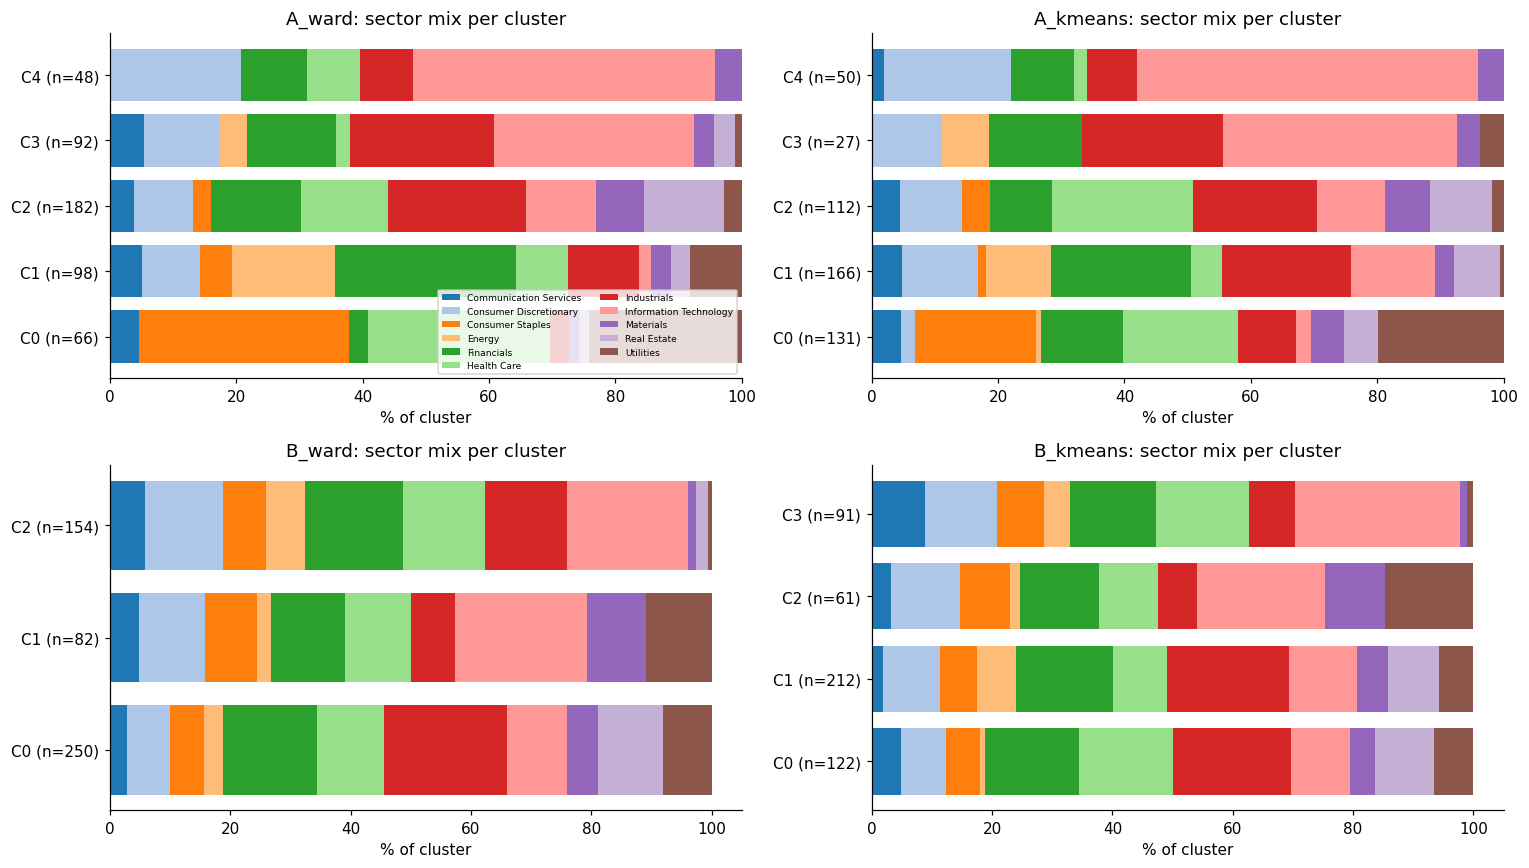

solution     chi2  p_value  cramers_V
  A_ward 354.8364      0.0     0.4272
A_kmeans 272.8238      0.0     0.3746
  B_ward  66.3242      0.0     0.2612
B_kmeans  78.2654      0.0     0.2317


In [29]:
# 3.2.1a Sector composition of every cluster
def cramers_v(table):
    """Association between two categorical variables (0 = none, 1 = perfect)."""
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))


sector_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sectors = sorted(feat["sector"].unique())
sector_colors = dict(zip(sectors, plt.get_cmap("tab20").colors))
for ax, s in zip(axes.ravel(), SOLUTIONS):
    ct = pd.crosstab(feat[s], feat["sector"])
    share = ct.div(ct.sum(axis=1), axis=0) * 100               # % of each cluster in each sector
    share.round(1).to_csv(TAB / f"t3_sector_share_{s}.csv")
    left = np.zeros(len(share))
    for sec in sectors:
        vals = share[sec].values if sec in share else np.zeros(len(share))
        ax.barh([f"C{c} (n={ct.loc[c].sum()})" for c in share.index], vals, left=left,
                color=sector_colors[sec], label=sec)
        left += vals
    ax.set_xlabel("% of cluster"); ax.set_title(f"{s}: sector mix per cluster")
    chi2, p, _, _ = chi2_contingency(ct, correction=False)
    sector_rows.append({"solution": s, "chi2": chi2, "p_value": p, "cramers_V": cramers_v(ct)})
axes[0, 0].legend(fontsize=6, ncol=2, loc="lower right")
save_fig(fig, "f3_1_sector_composition.png")
sector_assoc = pd.DataFrame(sector_rows).round(4)
sector_assoc.to_csv(TAB / "t3_sector_association.csv", index=False)
print(sector_assoc.to_string(index=False))
results["sector_association"] = sector_assoc.set_index("solution").to_dict("index")

> **Task 3.2.1 · Risk-return vs RFM clusters** · *7 marks*
>
>
>
> **This cell:** Crosstabs and ARI between matrix A and matrix B clusters. Low agreement means the two segmentations capture different things.
>
> **Output:** `tables/t3_crosstab_A_vs_B_*.csv`, `tables/t3_A_vs_B_agreement.csv`, `figures/f3_2_risk_vs_rfm_crosstab.png`.

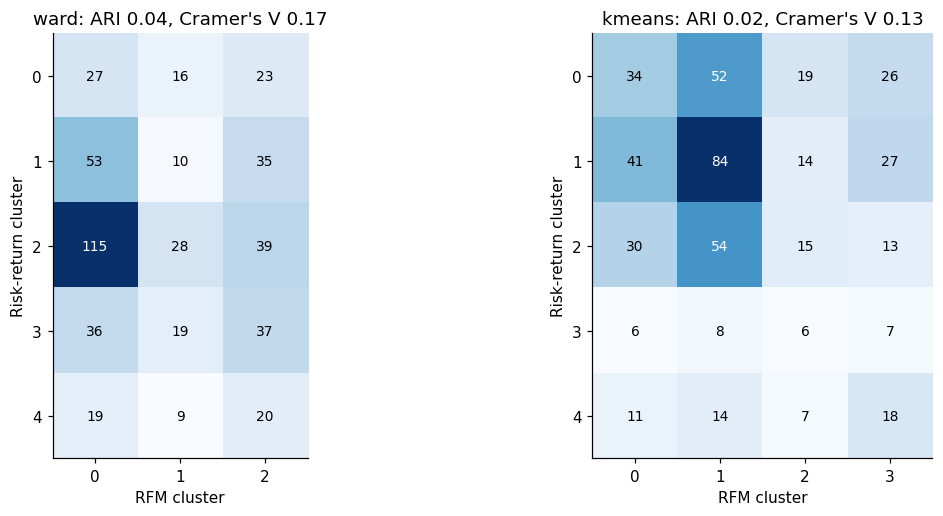

algorithm  ARI_A_vs_B  cramers_V
     ward      0.0393     0.1656
   kmeans      0.0210     0.1296


In [30]:
# 3.2.1b Risk-return clusters vs RFM clusters (same shares)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cross_rows = []
for ax, algo in zip(axes, ("ward", "kmeans")):
    a, b = feat[f"A_{algo}"], feat[f"B_{algo}"]
    ct = pd.crosstab(a.rename("risk-return cluster"), b.rename("RFM cluster"))
    ct.to_csv(TAB / f"t3_crosstab_A_vs_B_{algo}.csv")
    ari, v = adjusted_rand_score(a, b), cramers_v(ct)
    cross_rows.append({"algorithm": algo, "ARI_A_vs_B": ari, "cramers_V": v})
    ax.imshow(ct.values, cmap="Blues")
    ax.set_xticks(range(ct.shape[1]), ct.columns); ax.set_yticks(range(ct.shape[0]), ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=9,
                    color="white" if ct.values[i, j] > ct.values.max() * 0.6 else "black")
    ax.set_xlabel("RFM cluster"); ax.set_ylabel("Risk-return cluster")
    ax.set_title(f"{algo}: ARI {ari:.2f}, Cramer's V {v:.2f}")
save_fig(fig, "f3_2_risk_vs_rfm_crosstab.png")
cross = pd.DataFrame(cross_rows).round(4)
cross.to_csv(TAB / "t3_A_vs_B_agreement.csv", index=False)
print(cross.to_string(index=False))
results["A_vs_B_agreement"] = cross.set_index("algorithm").to_dict("index")

> **Task 3.2.3 · Limitation: return dependencies**
>
>
>
> **This cell:** Average pairwise weekly-return correlation for pairs inside the same cluster vs pairs in different clusters, tested against random labelling with the same cluster sizes; also plots correlation against the beta gap between two shares.
>
> **Output:** `tables/t3_return_dependence.csv`, `figures/f3_3_beta_gap_vs_correlation.png`.

     solution  within_cluster_mean_corr  across_cluster_mean_corr  random_label_within_mean  random_label_within_sd  z_vs_random
       A_ward                    0.3594                    0.2802                    0.2995                  0.0028      21.6729
     A_kmeans                    0.3499                    0.2823                    0.2996                  0.0020      24.8223
       B_ward                    0.3123                    0.2913                    0.2995                  0.0021       6.1709
     B_kmeans                    0.3142                    0.2931                    0.2997                  0.0025       5.7283
sector (GICS)                    0.4144                    0.2851                       NaN                     NaN          NaN
Residual (beta-removed) correlation: {'all_pairs_mean_corr': 0.29951296125978927, 'residual_same_sector_mean_corr': 0.17295168732979038, 'residual_diff_sector_mean_corr': 0.036750082416147946}
Pairs with beta within 0.05: {'n_

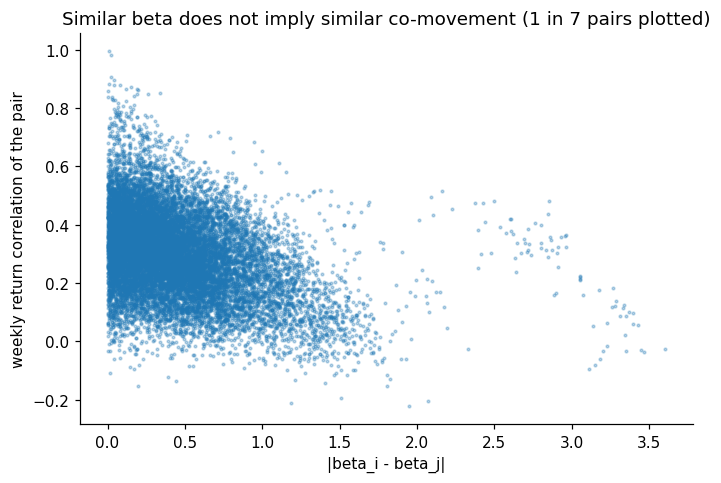

In [31]:
# 3.2.3a Return dependencies: do clusters group shares that move together?
# Similar beta does not mean similar co-movement. Compare average pairwise correlation of
# weekly returns for pairs INSIDE the same cluster vs pairs in DIFFERENT clusters, and
# against random labelling (permutation) with identical cluster sizes.
C = ret.corr().values
iu = np.triu_indices_from(C, k=1)                        # each pair counted once
corr_all = C[iu]
tickers = list(ret.columns)


def within_across(labels):
    labels = np.asarray(labels)
    same = (labels[:, None] == labels[None, :])[iu]
    return corr_all[same].mean(), corr_all[~same].mean()


dep_rows = []
for s in SOLUTIONS:
    lab = feat.loc[tickers, s].values
    w, a = within_across(lab)
    perm = np.array([within_across(rng.permutation(lab))[0] for _ in range(N_PERMUTATIONS)])
    dep_rows.append({"solution": s, "within_cluster_mean_corr": w, "across_cluster_mean_corr": a,
                     "random_label_within_mean": perm.mean(), "random_label_within_sd": perm.std(),
                     "z_vs_random": (w - perm.mean()) / perm.std()})

# Same question for sectors (a "natural" grouping), and on market-model RESIDUALS:
# after removing each share's beta exposure, are same-sector shares still correlated?
resid = ret.sub(ret_m.values[:, None] * feat.loc[tickers, "beta"].values[None, :], axis=1)
resid = resid.sub(resid.mean())                          # remove intercepts
Cr = resid.corr().values[iu]
sec = feat.loc[tickers, "sector"].to_numpy(dtype=object)   # plain numpy so [:, None] indexing works
same_sec = (sec[:, None] == sec[None, :])[iu]
dep_rows.append({"solution": "sector (GICS)", "within_cluster_mean_corr": corr_all[same_sec].mean(),
                 "across_cluster_mean_corr": corr_all[~same_sec].mean(), "random_label_within_mean": np.nan,
                 "random_label_within_sd": np.nan, "z_vs_random": np.nan})
dep = pd.DataFrame(dep_rows).round(4)
dep.to_csv(TAB / "t3_return_dependence.csv", index=False)
print(dep.to_string(index=False))
resid_summary = {"all_pairs_mean_corr": float(corr_all.mean()),
                 "residual_same_sector_mean_corr": float(Cr[same_sec].mean()),
                 "residual_diff_sector_mean_corr": float(Cr[~same_sec].mean())}
print("Residual (beta-removed) correlation:", resid_summary)
results["return_dependence"] = dep.set_index("solution").to_dict("index")
results["residual_dependence"] = resid_summary

# Beta similarity vs co-movement: pairs with near-identical beta but low/high correlation
b = feat.loc[tickers, "beta"].values
close_beta = (np.abs(b[:, None] - b[None, :]) < 0.05)[iu]
results["pairs_beta_within_0.05"] = {"n_pairs": int(close_beta.sum()),
                                     "corr_min": float(corr_all[close_beta].min()),
                                     "corr_median": float(np.median(corr_all[close_beta])),
                                     "corr_max": float(corr_all[close_beta].max())}
print("Pairs with beta within 0.05:", results["pairs_beta_within_0.05"])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(np.abs(b[:, None] - b[None, :])[iu][::7], corr_all[::7], s=3, alpha=0.3)
ax.set_xlabel("|beta_i - beta_j|"); ax.set_ylabel("weekly return correlation of the pair")
ax.set_title("Similar beta does not imply similar co-movement (1 in 7 pairs plotted)")
save_fig(fig, "f3_3_beta_gap_vs_correlation.png")

> **Task 3.2.3 · Limitation: price adjustment** ·
>
>
>
> **This cell:** Recomputes beta and mean weekly return from unadjusted Close (same week rules) and measures how far they move from the Adj Close versions.
>
> **Output:** `tables/t3_adjusted_vs_close_betas.csv`.

In [32]:
# 3.2.3b Price-adjustment assumption: Adj Close vs Close betas
# Recompute weekly returns/betas from CLOSE (split-adjusted, not dividend-adjusted) and compare.
prices = pd.read_parquet(RAW / "prices_daily.parquet")
prices["date"] = pd.to_datetime(prices["date"])
bench = pd.read_csv(RAW / "gspc_daily.csv", index_col=0, parse_dates=True)


def weekly_returns_from(daily):
    """Friday-ending weekly returns; same week rules as script 01 (drop incomplete first/last week)."""
    w = daily.resample("W-FRI").last()
    monday = w.index - pd.Timedelta(days=4)
    w = w[(monday >= pd.Timestamp(START)) & (w.index <= pd.Timestamp(END) - pd.Timedelta(days=1))]
    return w.pct_change().iloc[1:]


close = prices[prices.Ticker.isin(feat.index)].pivot(index="date", columns="Ticker", values="Close")[feat.index]
ret_close = weekly_returns_from(close)
rm_close = weekly_returns_from(bench[["Close"]])["Close"]
assert ret_close.index.equals(ret.index) and rm_close.index.equals(ret_m.index)
beta_close = ret_close.apply(lambda s: s.cov(rm_close)) / rm_close.var()
adj_gap = pd.DataFrame({"beta_adj": feat["beta"], "beta_close": beta_close,
                        "mean_ret_adj": feat["mean_weekly_return"], "mean_ret_close": ret_close.mean()})
adj_gap["beta_diff"] = adj_gap.beta_adj - adj_gap.beta_close
adj_gap["mean_ret_diff_pct_wk"] = (adj_gap.mean_ret_adj - adj_gap.mean_ret_close) * 100
adj_gap.round(5).to_csv(TAB / "t3_adjusted_vs_close_betas.csv")
adj_summary = {"corr_beta_adj_vs_close": float(adj_gap.beta_adj.corr(adj_gap.beta_close)),
               "mean_abs_beta_diff": float(adj_gap.beta_diff.abs().mean()),
               "max_abs_beta_diff": float(adj_gap.beta_diff.abs().max()),
               "mean_return_uplift_pct_per_week": float(adj_gap.mean_ret_diff_pct_wk.mean()),
               "mean_return_uplift_pct_annualised_approx": float(adj_gap.mean_ret_diff_pct_wk.mean() * 52),
               "benchmark_adj_equals_close": bool(np.allclose(bench["Adj Close"], bench["Close"]))
               if "Adj Close" in bench else None}
print("Adjusted vs Close:", adj_summary)
results["adjustment_check"] = adj_summary

Adjusted vs Close: {'corr_beta_adj_vs_close': 0.9999469619141371, 'mean_abs_beta_diff': 0.0025995479914803572, 'max_abs_beta_diff': 0.017116125595008413, 'mean_return_uplift_pct_per_week': 0.034729396557889, 'mean_return_uplift_pct_annualised_approx': 1.805928621010228, 'benchmark_adj_equals_close': True}


> **Task 3.2.3 · Limitation: survivorship bias** ·
>
>
>
> **This cell:** Compares shares added to the index after 1 Jan 2021 with those already in it: mean/median weekly return and beta, with a Mann-Whitney test.
>
> **Output:** `tables/t3_survivorship_evidence.csv`.

In [33]:
# 3.2.3c Survivorship bias evidence: shares added to the index during/after the study start
cons = pd.read_csv(RAW / "sp500_constituents.csv")
cons["ticker"] = cons["Symbol"].str.replace(".", "-", regex=False)
cons["date_added"] = pd.to_datetime(cons["Date added"], errors="coerce")
feat = feat.join(cons.set_index("ticker")["date_added"])
late = feat["date_added"] > pd.Timestamp(START)          # joined the index after the study began
surv = pd.DataFrame({
    "group": ["added to index after 2021-01-01", "already constituents at 2021-01-01 (or date unknown)"],
    "n_shares": [int(late.sum()), int((~late).sum())],
    "mean_weekly_return_pct": [feat.loc[late, "mean_weekly_return"].mean() * 100,
                               feat.loc[~late, "mean_weekly_return"].mean() * 100],
    "median_weekly_return_pct": [feat.loc[late, "mean_weekly_return"].median() * 100,
                                 feat.loc[~late, "mean_weekly_return"].median() * 100],
    "mean_beta": [feat.loc[late, "beta"].mean(), feat.loc[~late, "beta"].mean()]}).round(4)
surv.to_csv(TAB / "t3_survivorship_evidence.csv", index=False)
stat, p = mannwhitneyu(feat.loc[late, "mean_weekly_return"], feat.loc[~late, "mean_weekly_return"])
print(surv.to_string(index=False), f"\nMann-Whitney p = {p:.4f}")
results["survivorship"] = {"n_added_after_start": int(late.sum()), "n_total": int(len(feat)),
                           "mann_whitney_p": float(p), "table": surv.to_dict("records")}
print("Note: shares REMOVED from the index before the retrieval date are absent from the data entirely.")

                                               group  n_shares  mean_weekly_return_pct  median_weekly_return_pct  mean_beta
                     added to index after 2021-01-01        72                  0.4669                    0.4453     1.3222
already constituents at 2021-01-01 (or date unknown)       414                  0.2542                    0.2542     0.9131 
Mann-Whitney p = 0.0000
Note: shares REMOVED from the index before the retrieval date are absent from the data entirely.


> **Task 3.2 · Results file**
>
> **Brief:** Reproducible evidence for the 500-word review.
>
> **This cell:** Saves the key Task 3.2 numbers.
>
> **Output:** `data/processed/task3_results.json`.

In [34]:
# Save results for the report
(PROC / "task3_results.json").write_text(json.dumps(results, indent=2, default=float))
print("Task 3 analysis complete. Next")

Task 3 analysis complete. Next


---
**End of notebook.** All outputs are in `data/processed/`, `tables/` and `figures/`.